# Manuscript tables and figures

Post-processing, consistency audit and generation of the main and supplementary figures.

Part of the code for *Robust Non-Motor Symptom Modeling for Parkinson's Disease Differential Diagnosis*. See the repository README for the run order.

In [ ]:
# Exact reproduction requires XGBoost 3.3.0 (restart the runtime after installing)
!pip install -q xgboost==3.3.0

## Final post-processing and consistency audit

Q1 MANUSCRIPT FINAL POST-PROCESSING
Feature file        : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Model-J predictions : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_j_nms_ablation_shap_subgroups/model_j_patient_predictions.csv
Model-J SHAP        : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_j_nms_ablation_shap_subgroups/model_j_global_shap_importance.csv
Output directory    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing

TASK 1 — PRIMARY NMS-XGB BOOTSTRAP CONFIDENCE INTERVALS
           metric  estimate  ci_95_lower  ci_95_upper  bootstrap_samples
         accuracy  0.733333     0.687179     0.776923               2000
balanced_accuracy  0.726640     0.678386     0.

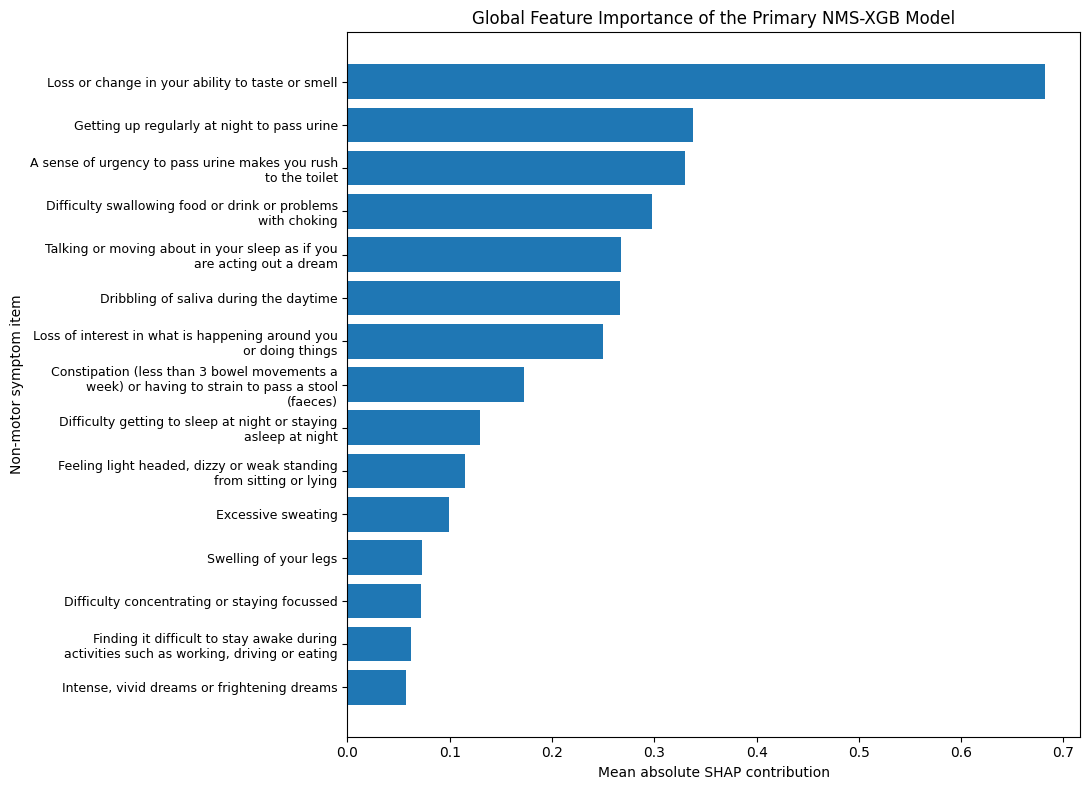

feature                                                                                  question_text  mean_absolute_shap
 nms_02                                               Loss or change in your ability to taste or smell            0.682039
 nms_09                                                    Getting up regularly at night to pass urine            0.338309
 nms_08                                  A sense of urgency to pass urine makes you rush to the toilet            0.330096
 nms_03                                   Difficulty swallowing food or drink or problems with choking            0.298005
 nms_25                         Talking or moving about in your sleep as if you are acting out a dream            0.267543
 nms_01                                                         Dribbling of saliva during the daytime            0.266383
 nms_13                               Loss of interest in what is happening around you or doing things            0.249413
 nms_05 Constipa

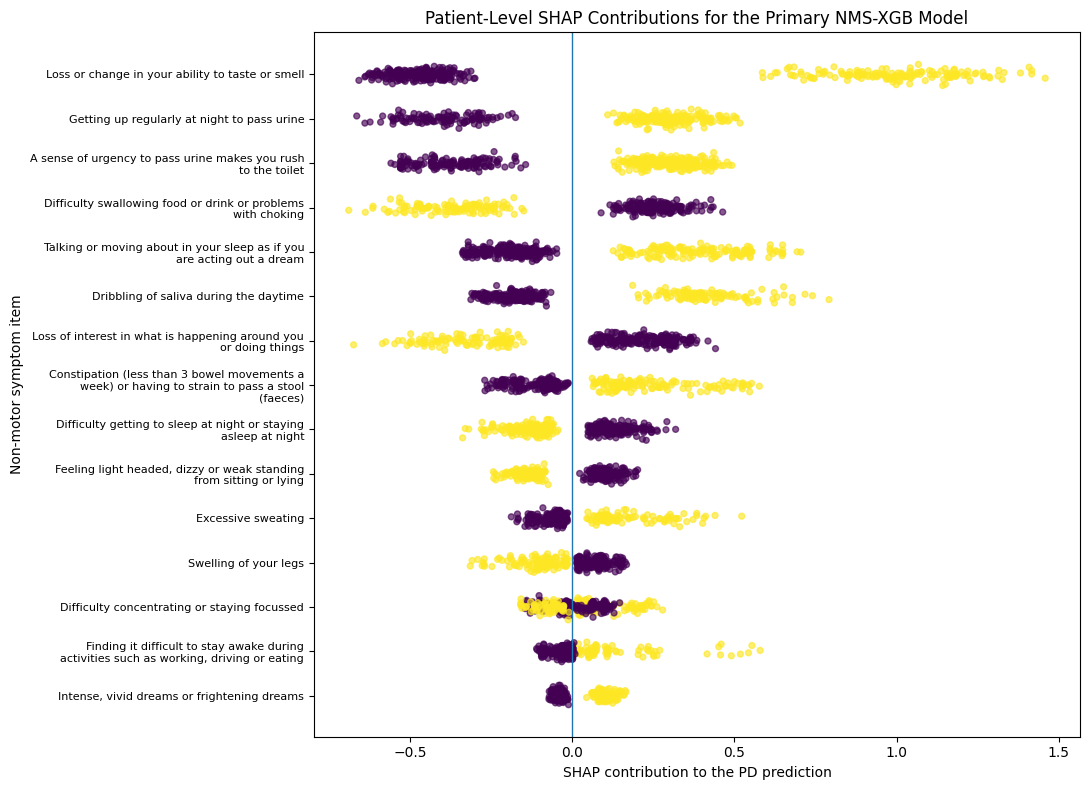


TASK 4 — SUBGROUP PERFORMANCE WITH 95% CONFIDENCE INTERVALS


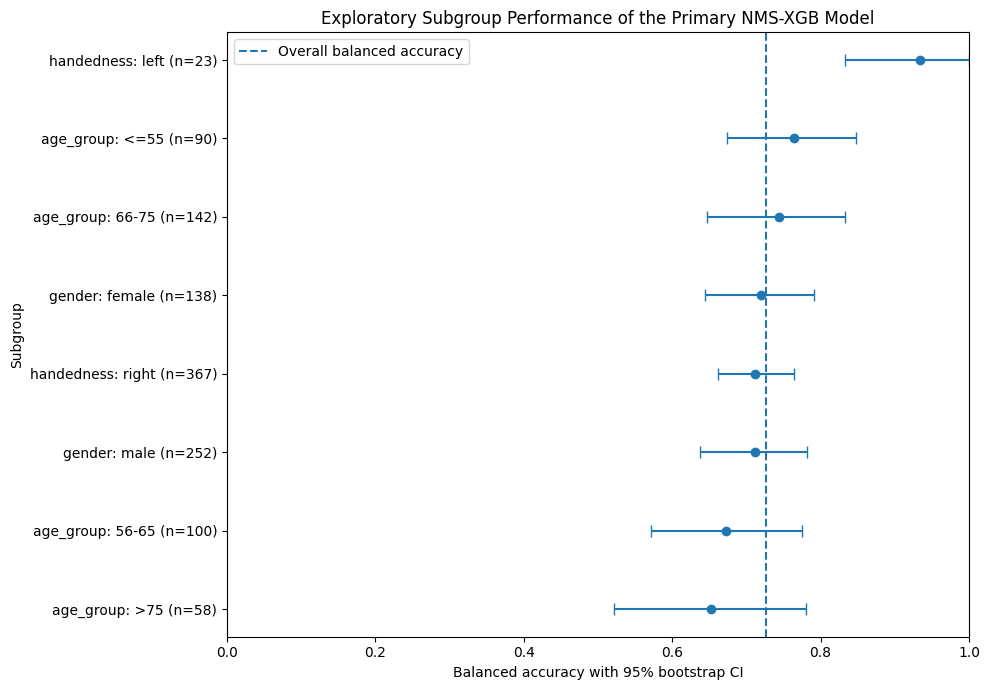

subgroup_variable subgroup_value  patients  pd_patients  dd_patients  balanced_accuracy  ba_ci_95_lower  ba_ci_95_upper  macro_f1  sensitivity_pd  specificity_dd  roc_auc small_subgroup_caution
        age_group            >75        58           40           18           0.652778        0.521081        0.779770  0.647773        0.750000        0.555556 0.698611                     No
        age_group          66-75       142          111           31           0.744115        0.647443        0.833217  0.714212        0.810811        0.677419 0.780006                     No
        age_group           <=55        90           54           36           0.763889        0.673359        0.847107  0.743653        0.666667        0.861111 0.795267                     No
        age_group          56-65       100           71           29           0.672657        0.571634        0.774423  0.648352        0.690141        0.655172 0.748179                     No
           gender           ma

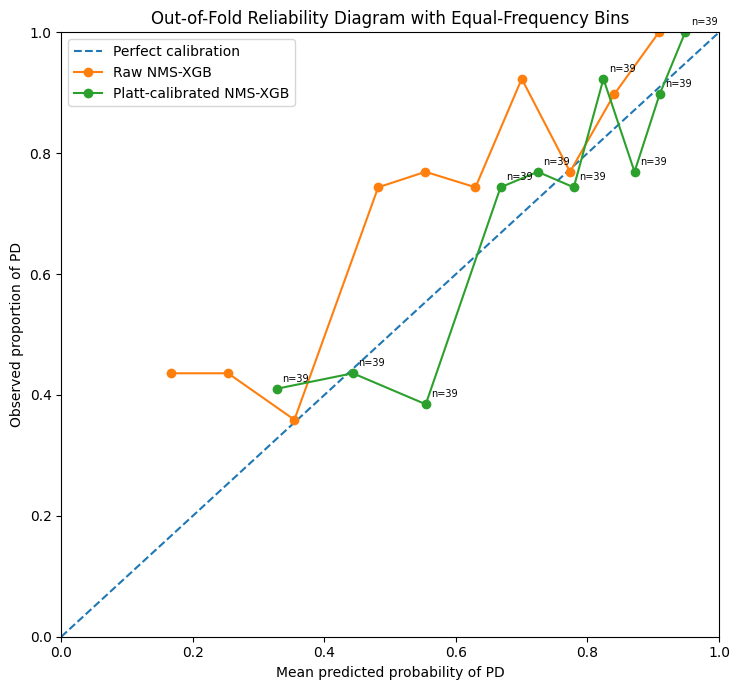

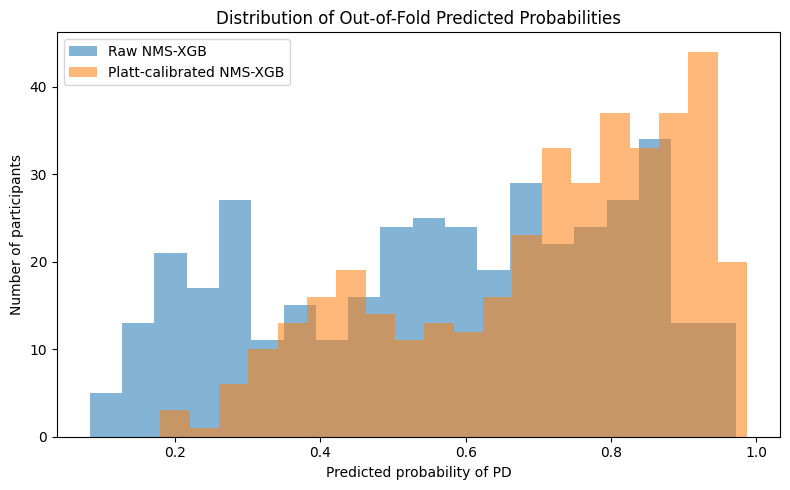


TASK 7 — DECISION-CURVE ANALYSIS


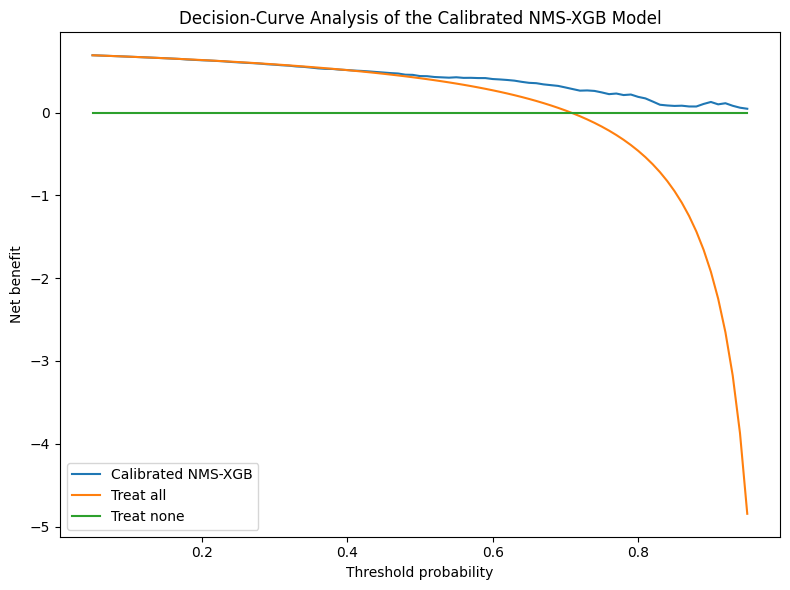

Observed thresholds with net benefit above both strategies:
0.40 to 0.95

Saved referral files:
 - /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_k_calibration_decision_cost_referral/model_k_referral_analysis_by_fold.csv
 - /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_k_calibration_decision_cost_referral/model_k_referral_patient_decisions.csv
 - /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_k_calibration_decision_cost_referral/model_k_referral_summary.csv

100% retained referral rows:
                                                                                                                                                                                       source_file  outer_fold  target_retained_coverage  actual_retained_coverage  confidence_cutoff  retained_pat

In [ ]:
# ==================================================================================================
# Q1 MANUSCRIPT — ONE-CELL FINAL POST-PROCESSING AND CONSISTENCY AUDIT
#
# This cell DOES NOT retrain Model J.
#
# It uses existing saved outputs to generate:
#   1. Primary NMS-XGB patient-level bootstrap 95% confidence intervals
#   2. Abstract-ready performance sentence
#   3. Cohort characteristics tables
#   4. DD diagnostic-composition table
#   5. Publication-quality SHAP bar plot with questionnaire text
#   6. SHAP beeswarm-style plot
#   7. Subgroup performance with bootstrap confidence intervals
#   8. Calibration/referral consistency audit, when calibrated predictions are available
#   9. Equal-frequency reliability diagram, when calibrated predictions are available
#  10. Decision-curve analysis, when calibrated predictions are available
#  11. NTR-XGB Table 3/Table 5 audit, when NTR patient predictions are available
#
# Required:
#   - Existing Model-J output folder
#   - pads_engineered_features.csv
#
# Run after mounting/restoring the project_ready_data folder.
# ==================================================================================================

import re
import json
import textwrap
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. CONFIGURATION AND PATHS
# ==================================================================================================

GLOBAL_SEED = 42
N_BOOTSTRAPS = 2000
N_CALIBRATION_BINS = 10

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"

FEATURE_FILE = (
    PROJECT_DIR
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

MODEL_J_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_j_nms_ablation_shap_subgroups"
)

FINAL_OUTPUT_DIR = (
    PROJECT_DIR
    / "manuscript_final_postprocessing"
)

FINAL_FIGURE_DIR = (
    FINAL_OUTPUT_DIR
    / "figures"
)

FINAL_TABLE_DIR = (
    FINAL_OUTPUT_DIR
    / "tables"
)

FINAL_AUDIT_DIR = (
    FINAL_OUTPUT_DIR
    / "audits"
)

for directory in [
    FINAL_OUTPUT_DIR,
    FINAL_FIGURE_DIR,
    FINAL_TABLE_DIR,
    FINAL_AUDIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


def locate_file(
    expected_path,
    filename
):
    expected_path = Path(
        expected_path
    )

    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file not found: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

MODEL_J_PREDICTION_FILE = locate_file(
    MODEL_J_DIR
    / "model_j_patient_predictions.csv",
    "model_j_patient_predictions.csv"
)

MODEL_J_SHAP_IMPORTANCE_FILE = locate_file(
    MODEL_J_DIR
    / "model_j_global_shap_importance.csv",
    "model_j_global_shap_importance.csv"
)

MODEL_J_SHAP_VALUES_FILE = locate_file(
    MODEL_J_DIR
    / "model_j_patient_level_shap_values.csv",
    "model_j_patient_level_shap_values.csv"
)

MODEL_J_MAPPING_FILE = locate_file(
    MODEL_J_DIR
    / "model_j_nms_question_mapping.csv",
    "model_j_nms_question_mapping.csv"
)

print("=" * 115)
print("Q1 MANUSCRIPT FINAL POST-PROCESSING")
print("=" * 115)

print("Feature file        :", FEATURE_FILE)
print("Model-J predictions :", MODEL_J_PREDICTION_FILE)
print("Model-J SHAP        :", MODEL_J_SHAP_IMPORTANCE_FILE)
print("Output directory    :", FINAL_OUTPUT_DIR)

# ==================================================================================================
# 2. GENERAL HELPERS
# ==================================================================================================

def detect_column(
    dataframe,
    candidates,
    contains=None
):
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    if contains is not None:
        for column in dataframe.columns:
            normalized = str(
                column
            ).lower()

            if all(
                keyword.lower()
                in normalized
                for keyword in contains
            ):
                return column

    return None


def normalize_patient_ids(
    series
):
    return (
        series
        .astype(str)
        .str.replace(
            ".0",
            "",
            regex=False
        )
        .str.zfill(3)
    )


def expected_calibration_error(
    labels,
    probabilities,
    number_of_bins=10
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    edges = np.linspace(
        0.0,
        1.0,
        number_of_bins + 1
    )

    ece = 0.0

    for bin_index in range(
        number_of_bins
    ):
        lower = edges[
            bin_index
        ]

        upper = edges[
            bin_index + 1
        ]

        if (
            bin_index
            == number_of_bins - 1
        ):
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if np.any(mask):
            observed = np.mean(
                labels[mask]
            )

            predicted = np.mean(
                probabilities[mask]
            )

            ece += (
                np.mean(mask)
                * abs(
                    observed
                    - predicted
                )
            )

    return float(ece)


def calculate_metrics(
    labels,
    predictions,
    probabilities
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            labels,
            predictions
        ),

        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": sensitivity,
        "specificity_dd": specificity,

        "roc_auc": roc_auc_score(
            labels,
            probabilities
        ),

        "pr_auc": average_precision_score(
            labels,
            probabilities
        ),

        "brier_score": brier_score_loss(
            labels,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            labels,
            probabilities,
            number_of_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def bootstrap_metric_intervals(
    labels,
    predictions,
    probabilities,
    number_of_bootstraps=2000,
    seed=42
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    observed = calculate_metrics(
        labels,
        predictions,
        probabilities
    )

    rng = np.random.default_rng(
        seed
    )

    metric_names = [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]

    bootstrap_values = {
        metric: []
        for metric in metric_names
    }

    number_of_patients = len(
        labels
    )

    for _ in range(
        number_of_bootstraps
    ):
        sampled_indices = rng.integers(
            0,
            number_of_patients,
            size=number_of_patients
        )

        sampled_labels = labels[
            sampled_indices
        ]

        if len(
            np.unique(
                sampled_labels
            )
        ) < 2:
            continue

        sampled_metrics = calculate_metrics(
            sampled_labels,

            predictions[
                sampled_indices
            ],

            probabilities[
                sampled_indices
            ]
        )

        for metric in metric_names:
            value = sampled_metrics[
                metric
            ]

            if np.isfinite(value):
                bootstrap_values[
                    metric
                ].append(value)

    interval_rows = []

    for metric in metric_names:
        values = np.asarray(
            bootstrap_values[
                metric
            ],
            dtype=float
        )

        interval_rows.append({
            "metric": metric,

            "estimate": float(
                observed[
                    metric
                ]
            ),

            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),

            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            ),

            "bootstrap_samples": int(
                len(values)
            )
        })

    return (
        observed,
        pd.DataFrame(
            interval_rows
        )
    )


def safe_read_csv(
    path
):
    try:
        return pd.read_csv(
            path
        )

    except Exception as error:
        print(
            "Could not read:",
            path,
            "|",
            str(error)[:150]
        )

        return None


def normalize_category(
    series
):
    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .replace({
            "": np.nan,
            "nan": np.nan,
            "none": np.nan,
            "null": np.nan
        })
    )


def wrap_labels(
    values,
    width=44
):
    return [
        textwrap.fill(
            str(value),
            width=width
        )
        for value in values
    ]


postprocessing_summary = []

# ==================================================================================================
# 3. LOAD AND VALIDATE PRIMARY MODEL-J PREDICTIONS
# ==================================================================================================

prediction_df = pd.read_csv(
    MODEL_J_PREDICTION_FILE
)

patient_id_column = detect_column(
    prediction_df,
    [
        "patient_id",
        "participant_id",
        "subject_id",
        "id"
    ]
)

configuration_column = detect_column(
    prediction_df,
    [
        "configuration",
        "model",
        "model_name"
    ]
)

true_label_column = detect_column(
    prediction_df,
    [
        "true_label",
        "y_true",
        "label",
        "y"
    ]
)

probability_column = detect_column(
    prediction_df,
    [
        "predicted_probability_pd",
        "probability_pd",
        "predicted_probability",
        "probability",
        "y_probability",
        "y_prob"
    ]
)

prediction_column = detect_column(
    prediction_df,
    [
        "predicted_label",
        "prediction",
        "y_pred"
    ]
)

fold_column = detect_column(
    prediction_df,
    [
        "outer_fold",
        "fold"
    ]
)

required_prediction_columns = {
    "patient ID": patient_id_column,
    "true label": true_label_column,
    "probability": probability_column,
    "prediction": prediction_column
}

missing_prediction_columns = [
    name
    for name, column
    in required_prediction_columns.items()
    if column is None
]

if missing_prediction_columns:
    raise RuntimeError(
        "Model-J prediction file is missing: "
        + ", ".join(
            missing_prediction_columns
        )
    )

prediction_df[
    patient_id_column
] = normalize_patient_ids(
    prediction_df[
        patient_id_column
    ]
)

primary_df = (
    prediction_df
    .copy()
)

if configuration_column is not None:
    normalized_configuration = (
        primary_df[
            configuration_column
        ]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    exact_mask = (
        normalized_configuration
        == "nms_items_only"
    )

    if exact_mask.any():
        primary_df = (
            primary_df.loc[
                exact_mask
            ]
            .copy()
        )

    else:
        approximate_mask = (
            normalized_configuration
            .str.contains(
                "nms.*items.*only",
                regex=True,
                na=False
            )
        )

        if approximate_mask.any():
            primary_df = (
                primary_df.loc[
                    approximate_mask
                ]
                .copy()
            )

primary_df = (
    primary_df
    .drop_duplicates(
        subset=[
            patient_id_column
        ],
        keep="last"
    )
    .sort_values(
        patient_id_column
    )
    .reset_index(drop=True)
)

if len(primary_df) != 390:
    raise RuntimeError(
        "Expected 390 primary NMS-XGB predictions, "
        f"but found {len(primary_df)}."
    )

primary_patient_ids = (
    primary_df[
        patient_id_column
    ]
    .to_numpy()
)

primary_y = pd.to_numeric(
    primary_df[
        true_label_column
    ],
    errors="raise"
).astype(int).to_numpy()

primary_probabilities = pd.to_numeric(
    primary_df[
        probability_column
    ],
    errors="raise"
).astype(float).to_numpy()

primary_predictions = pd.to_numeric(
    primary_df[
        prediction_column
    ],
    errors="raise"
).astype(int).to_numpy()

if len(
    np.unique(
        primary_patient_ids
    )
) != 390:
    raise RuntimeError(
        "Primary prediction file contains duplicate patient IDs."
    )

# ==================================================================================================
# 4. PRIMARY NMS-XGB BOOTSTRAP CONFIDENCE INTERVALS
# ==================================================================================================

print("\n" + "=" * 115)
print("TASK 1 — PRIMARY NMS-XGB BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 115)

primary_metrics, primary_ci_df = (
    bootstrap_metric_intervals(
        labels=primary_y,
        predictions=primary_predictions,
        probabilities=primary_probabilities,
        number_of_bootstraps=N_BOOTSTRAPS,
        seed=GLOBAL_SEED
    )
)

primary_ci_df.to_csv(
    FINAL_TABLE_DIR
    / "primary_nms_xgb_bootstrap_ci.csv",
    index=False
)

primary_ci_df.to_latex(
    FINAL_TABLE_DIR
    / "primary_nms_xgb_bootstrap_ci.tex",
    index=False,
    float_format="%.4f"
)

print(
    primary_ci_df.to_string(
        index=False
    )
)

ba_ci_row = (
    primary_ci_df.loc[
        primary_ci_df["metric"]
        == "balanced_accuracy"
    ]
    .iloc[0]
)

macro_f1_ci_row = (
    primary_ci_df.loc[
        primary_ci_df["metric"]
        == "macro_f1"
    ]
    .iloc[0]
)

abstract_sentence = (
    "The NMS-XGB model achieved a balanced accuracy of "
    f"{100 * ba_ci_row['estimate']:.2f}% "
    f"(95% CI: {100 * ba_ci_row['ci_95_lower']:.2f}%--"
    f"{100 * ba_ci_row['ci_95_upper']:.2f}%), "
    f"Macro-F1 of {100 * macro_f1_ci_row['estimate']:.2f}%, "
    f"sensitivity of {100 * primary_metrics['sensitivity_pd']:.2f}%, "
    f"specificity of {100 * primary_metrics['specificity_dd']:.2f}%, "
    f"and ROC-AUC of {primary_metrics['roc_auc']:.4f}."
)

(
    FINAL_OUTPUT_DIR
    / "abstract_primary_result_sentence.txt"
).write_text(
    abstract_sentence,
    encoding="utf-8"
)

print("\nAbstract-ready primary result:")
print(abstract_sentence)

postprocessing_summary.append({
    "task": "Primary bootstrap confidence intervals",
    "status": "Completed",
    "output": (
        "tables/primary_nms_xgb_bootstrap_ci.csv"
    )
})

# ==================================================================================================
# 5. COHORT CHARACTERISTICS AND DD COMPOSITION
# ==================================================================================================

print("\n" + "=" * 115)
print("TASK 2 — COHORT CHARACTERISTICS")
print("=" * 115)

feature_df = pd.read_csv(
    FEATURE_FILE
)

feature_patient_id_column = detect_column(
    feature_df,
    [
        "patient_id",
        "participant_id",
        "subject_id",
        "id"
    ]
)

feature_target_column = detect_column(
    feature_df,
    [
        "y",
        "true_label",
        "target",
        "label",
        "condition_2class",
        "diagnostic_group"
    ]
)

if (
    feature_patient_id_column
    is None
    or feature_target_column
    is None
):
    raise RuntimeError(
        "Feature file must contain patient ID and target columns."
    )

feature_df[
    feature_patient_id_column
] = normalize_patient_ids(
    feature_df[
        feature_patient_id_column
    ]
)

feature_df[
    feature_target_column
] = pd.to_numeric(
    feature_df[
        feature_target_column
    ],
    errors="raise"
).astype(int)

feature_df = (
    feature_df
    .drop_duplicates(
        subset=[
            feature_patient_id_column
        ],
        keep="last"
    )
)

cohort_df = (
    feature_df
    .set_index(
        feature_patient_id_column
    )
    .reindex(
        primary_patient_ids
    )
    .reset_index()
)

if cohort_df[
    feature_target_column
].isna().any():
    raise RuntimeError(
        "Some Model-J patients were not found in the feature file."
    )

cohort_df["group"] = np.where(
    cohort_df[
        feature_target_column
    ].astype(int) == 1,
    "PD",
    "DD"
)

continuous_candidates = [
    "age",
    "height",
    "weight",
    "bmi"
]

continuous_columns = [
    column
    for column in continuous_candidates
    if column in cohort_df.columns
]

categorical_candidates = [
    "gender",
    "sex",
    "handedness"
]

categorical_columns = [
    column
    for column in categorical_candidates
    if column in cohort_df.columns
]

cohort_characteristic_rows = []

group_definitions = [
    ("PD", cohort_df["group"] == "PD"),
    ("DD", cohort_df["group"] == "DD"),
    ("Overall", np.ones(len(cohort_df), dtype=bool))
]

for group_name, mask in group_definitions:

    subset = cohort_df.loc[
        mask
    ]

    cohort_characteristic_rows.append({
        "group": group_name,
        "variable": "Participants",
        "level_or_statistic": "n",
        "value": str(
            len(subset)
        ),
        "missing_n": 0
    })

    for column in continuous_columns:

        numeric_values = pd.to_numeric(
            subset[column],
            errors="coerce"
        )

        valid_values = (
            numeric_values
            .dropna()
        )

        missing_count = int(
            numeric_values
            .isna()
            .sum()
        )

        if len(valid_values) == 0:
            continue

        mean_value = valid_values.mean()
        standard_deviation = valid_values.std(
            ddof=1
        )

        median_value = valid_values.median()
        first_quartile = valid_values.quantile(
            0.25
        )
        third_quartile = valid_values.quantile(
            0.75
        )

        cohort_characteristic_rows.append({
            "group": group_name,
            "variable": column,
            "level_or_statistic": "Mean ± SD",
            "value": (
                f"{mean_value:.2f} ± "
                f"{standard_deviation:.2f}"
            ),
            "missing_n": missing_count
        })

        cohort_characteristic_rows.append({
            "group": group_name,
            "variable": column,
            "level_or_statistic": "Median [IQR]",
            "value": (
                f"{median_value:.2f} "
                f"[{first_quartile:.2f}, "
                f"{third_quartile:.2f}]"
            ),
            "missing_n": missing_count
        })

    for column in categorical_columns:

        normalized_values = normalize_category(
            subset[column]
        )

        missing_count = int(
            normalized_values
            .isna()
            .sum()
        )

        valid_values = (
            normalized_values
            .dropna()
        )

        counts = (
            valid_values
            .value_counts(
                dropna=False
            )
        )

        denominator = len(
            valid_values
        )

        for level, count in counts.items():

            percentage = (
                100.0 * count / denominator
                if denominator > 0
                else np.nan
            )

            cohort_characteristic_rows.append({
                "group": group_name,
                "variable": column,
                "level_or_statistic": str(level),
                "value": (
                    f"{int(count)} "
                    f"({percentage:.1f}%)"
                ),
                "missing_n": missing_count
            })

cohort_characteristics_df = pd.DataFrame(
    cohort_characteristic_rows
)

cohort_characteristics_df.to_csv(
    FINAL_TABLE_DIR
    / "cohort_characteristics_long.csv",
    index=False
)

cohort_characteristics_df.to_latex(
    FINAL_TABLE_DIR
    / "cohort_characteristics_long.tex",
    index=False,
    escape=True
)

print(
    cohort_characteristics_df
    .head(30)
    .to_string(index=False)
)

# DD diagnostic composition
diagnosis_column_candidates = [
    "original_condition",
    "condition_original",
    "original_diagnosis",
    "diagnosis",
    "diagnostic_condition",
    "condition"
]

diagnosis_column = next(
    (
        column
        for column in diagnosis_column_candidates
        if column in cohort_df.columns
    ),
    None
)

if diagnosis_column is not None:

    dd_diagnosis = normalize_category(
        cohort_df.loc[
            cohort_df["group"]
            == "DD",
            diagnosis_column
        ]
    )

    dd_composition_df = (
        dd_diagnosis
        .value_counts(
            dropna=False
        )
        .rename_axis(
            "dd_diagnosis"
        )
        .reset_index(
            name="participants"
        )
    )

    dd_total = dd_composition_df[
        "participants"
    ].sum()

    dd_composition_df[
        "percentage"
    ] = (
        100.0
        * dd_composition_df[
            "participants"
        ]
        / dd_total
    )

    dd_composition_df.to_csv(
        FINAL_TABLE_DIR
        / "dd_diagnostic_composition.csv",
        index=False
    )

    dd_composition_df.to_latex(
        FINAL_TABLE_DIR
        / "dd_diagnostic_composition.tex",
        index=False,
        float_format="%.1f"
    )

    print("\nDD diagnostic composition:")
    print(
        dd_composition_df.to_string(
            index=False
        )
    )

    dd_status = "Completed"

else:

    print(
        "\nDD diagnostic-composition column "
        "was not found in the engineered feature file."
    )

    dd_status = "Skipped: diagnosis column unavailable"

postprocessing_summary.append({
    "task": "Cohort characteristics",
    "status": "Completed",
    "output": (
        "tables/cohort_characteristics_long.csv"
    )
})

postprocessing_summary.append({
    "task": "DD diagnostic composition",
    "status": dd_status,
    "output": (
        "tables/dd_diagnostic_composition.csv"
        if diagnosis_column is not None
        else ""
    )
})

# ==================================================================================================
# 6. PUBLICATION-QUALITY SHAP FIGURES
# ==================================================================================================

print("\n" + "=" * 115)
print("TASK 3 — PUBLICATION-QUALITY SHAP FIGURES")
print("=" * 115)

shap_importance_df = pd.read_csv(
    MODEL_J_SHAP_IMPORTANCE_FILE
)

question_mapping_df = pd.read_csv(
    MODEL_J_MAPPING_FILE
)

shap_configuration_column = detect_column(
    shap_importance_df,
    [
        "configuration",
        "model",
        "model_name"
    ]
)

shap_feature_column = detect_column(
    shap_importance_df,
    [
        "feature",
        "feature_name"
    ]
)

shap_value_column = detect_column(
    shap_importance_df,
    [
        "mean_absolute_shap",
        "mean_absolute_shap_value",
        "mean_abs_shap"
    ]
)

question_feature_column = detect_column(
    question_mapping_df,
    [
        "feature",
        "feature_name"
    ]
)

question_text_column = detect_column(
    question_mapping_df,
    [
        "question_text",
        "text",
        "question"
    ]
)

if (
    shap_feature_column is None
    or shap_value_column is None
):
    raise RuntimeError(
        "Required SHAP columns were not found."
    )

primary_shap_df = (
    shap_importance_df
    .copy()
)

if shap_configuration_column is not None:

    normalized_shap_configuration = (
        primary_shap_df[
            shap_configuration_column
        ]
        .astype(str)
        .str.lower()
    )

    shap_mask = (
        normalized_shap_configuration
        == "nms_items_only"
    )

    if shap_mask.any():
        primary_shap_df = (
            primary_shap_df.loc[
                shap_mask
            ]
            .copy()
        )

if (
    question_feature_column is not None
    and question_text_column is not None
):

    mapping_subset = (
        question_mapping_df[
            [
                question_feature_column,
                question_text_column
            ]
        ]
        .drop_duplicates(
            subset=[
                question_feature_column
            ]
        )
        .rename(
            columns={
                question_feature_column: (
                    shap_feature_column
                ),
                question_text_column: (
                    "question_text"
                )
            }
        )
    )

    if "question_text" not in primary_shap_df.columns:

        primary_shap_df = (
            primary_shap_df
            .merge(
                mapping_subset,
                on=shap_feature_column,
                how="left"
            )
        )

    else:

        primary_shap_df = (
            primary_shap_df
            .merge(
                mapping_subset,
                on=shap_feature_column,
                how="left",
                suffixes=(
                    "",
                    "_mapped"
                )
            )
        )

        primary_shap_df[
            "question_text"
        ] = (
            primary_shap_df[
                "question_text"
            ]
            .replace(
                "",
                np.nan
            )
            .fillna(
                primary_shap_df[
                    "question_text_mapped"
                ]
            )
        )

else:

    primary_shap_df[
        "question_text"
    ] = primary_shap_df[
        shap_feature_column
    ]

primary_shap_df[
    "question_text"
] = (
    primary_shap_df[
        "question_text"
    ]
    .fillna(
        primary_shap_df[
            shap_feature_column
        ]
    )
)

top_shap_df = (
    primary_shap_df
    .sort_values(
        shap_value_column,
        ascending=False
    )
    .head(15)
    .copy()
)

top_shap_df[
    "display_label"
] = wrap_labels(
    top_shap_df[
        "question_text"
    ],
    width=48
)

top_shap_df.to_csv(
    FINAL_TABLE_DIR
    / "primary_nms_xgb_top15_shap.csv",
    index=False
)

plot_shap_df = (
    top_shap_df
    .sort_values(
        shap_value_column,
        ascending=True
    )
)

plt.figure(
    figsize=(11, 8)
)

plt.barh(
    np.arange(
        len(plot_shap_df)
    ),
    plot_shap_df[
        shap_value_column
    ]
)

plt.yticks(
    np.arange(
        len(plot_shap_df)
    ),
    plot_shap_df[
        "display_label"
    ],
    fontsize=9
)

plt.xlabel(
    "Mean absolute SHAP contribution"
)

plt.ylabel(
    "Non-motor symptom item"
)

plt.title(
    "Global Feature Importance of the Primary NMS-XGB Model"
)

plt.tight_layout()

plt.savefig(
    FINAL_FIGURE_DIR
    / "primary_nms_xgb_shap_top15.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print(
    top_shap_df[
        [
            shap_feature_column,
            "question_text",
            shap_value_column
        ]
    ].to_string(
        index=False
    )
)

# SHAP beeswarm-style plot
try:

    patient_shap_df = pd.read_csv(
        MODEL_J_SHAP_VALUES_FILE
    )

    patient_shap_configuration_column = detect_column(
        patient_shap_df,
        [
            "configuration",
            "model",
            "model_name"
        ]
    )

    patient_shap_feature_column = detect_column(
        patient_shap_df,
        [
            "feature",
            "feature_name"
        ]
    )

    patient_shap_value_column = detect_column(
        patient_shap_df,
        [
            "shap_value",
            "contribution"
        ]
    )

    patient_feature_value_column = detect_column(
        patient_shap_df,
        [
            "feature_value",
            "value"
        ]
    )

    if (
        patient_shap_feature_column is not None
        and patient_shap_value_column is not None
    ):

        if (
            patient_shap_configuration_column
            is not None
        ):

            patient_configuration_mask = (
                patient_shap_df[
                    patient_shap_configuration_column
                ]
                .astype(str)
                .str.lower()
                == "nms_items_only"
            )

            if patient_configuration_mask.any():
                patient_shap_df = (
                    patient_shap_df.loc[
                        patient_configuration_mask
                    ]
                    .copy()
                )

        top_feature_order = (
            top_shap_df[
                shap_feature_column
            ]
            .tolist()
        )

        label_map = dict(
            zip(
                top_shap_df[
                    shap_feature_column
                ],
                top_shap_df[
                    "display_label"
                ]
            )
        )

        beeswarm_df = (
            patient_shap_df.loc[
                patient_shap_df[
                    patient_shap_feature_column
                ].isin(
                    top_feature_order
                )
            ]
            .copy()
        )

        y_position_map = {
            feature: position
            for position, feature
            in enumerate(
                reversed(
                    top_feature_order
                )
            )
        }

        rng = np.random.default_rng(
            GLOBAL_SEED
        )

        plt.figure(
            figsize=(11, 8)
        )

        for feature in reversed(
            top_feature_order
        ):

            feature_subset = (
                beeswarm_df.loc[
                    beeswarm_df[
                        patient_shap_feature_column
                    ]
                    == feature
                ]
            )

            if feature_subset.empty:
                continue

            y_center = y_position_map[
                feature
            ]

            jitter = rng.normal(
                loc=0.0,
                scale=0.08,
                size=len(
                    feature_subset
                )
            )

            if (
                patient_feature_value_column
                is not None
            ):

                color_values = pd.to_numeric(
                    feature_subset[
                        patient_feature_value_column
                    ],
                    errors="coerce"
                ).fillna(0.0)

                plt.scatter(
                    feature_subset[
                        patient_shap_value_column
                    ],
                    y_center + jitter,
                    c=color_values,
                    alpha=0.65,
                    s=18
                )

            else:

                plt.scatter(
                    feature_subset[
                        patient_shap_value_column
                    ],
                    y_center + jitter,
                    alpha=0.65,
                    s=18
                )

        ordered_features = list(
            reversed(
                top_feature_order
            )
        )

        plt.yticks(
            np.arange(
                len(
                    ordered_features
                )
            ),
            [
                label_map[
                    feature
                ]
                for feature
                in ordered_features
            ],
            fontsize=8
        )

        plt.axvline(
            0.0,
            linewidth=1
        )

        plt.xlabel(
            "SHAP contribution to the PD prediction"
        )

        plt.ylabel(
            "Non-motor symptom item"
        )

        plt.title(
            "Patient-Level SHAP Contributions for the Primary NMS-XGB Model"
        )

        plt.tight_layout()

        plt.savefig(
            FINAL_FIGURE_DIR
            / "primary_nms_xgb_shap_beeswarm.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        beeswarm_status = "Completed"

    else:
        beeswarm_status = (
            "Skipped: required SHAP columns unavailable"
        )

except Exception as error:

    print(
        "SHAP beeswarm skipped:",
        str(error)[:200]
    )

    beeswarm_status = (
        "Skipped due to file/schema issue"
    )

postprocessing_summary.append({
    "task": "Relabelled SHAP bar plot",
    "status": "Completed",
    "output": (
        "figures/primary_nms_xgb_shap_top15.png"
    )
})

postprocessing_summary.append({
    "task": "SHAP beeswarm",
    "status": beeswarm_status,
    "output": (
        "figures/primary_nms_xgb_shap_beeswarm.png"
        if beeswarm_status == "Completed"
        else ""
    )
})

# ==================================================================================================
# 7. SUBGROUP PERFORMANCE WITH BOOTSTRAP CONFIDENCE INTERVALS
# ==================================================================================================

print("\n" + "=" * 115)
print("TASK 4 — SUBGROUP PERFORMANCE WITH 95% CONFIDENCE INTERVALS")
print("=" * 115)

subgroup_df = cohort_df.copy()

primary_result_frame = pd.DataFrame({
    feature_patient_id_column: (
        primary_patient_ids
    ),

    "true_label_primary": (
        primary_y
    ),

    "probability_primary": (
        primary_probabilities
    ),

    "prediction_primary": (
        primary_predictions
    )
})

subgroup_df = (
    subgroup_df
    .merge(
        primary_result_frame,
        on=feature_patient_id_column,
        how="inner"
    )
)

subgroup_definitions = []

if "age" in subgroup_df.columns:

    subgroup_df[
        "age_numeric"
    ] = pd.to_numeric(
        subgroup_df["age"],
        errors="coerce"
    )

    subgroup_df[
        "age_group"
    ] = pd.cut(
        subgroup_df[
            "age_numeric"
        ],
        bins=[
            -np.inf,
            55,
            65,
            75,
            np.inf
        ],
        labels=[
            "<=55",
            "56-65",
            "66-75",
            ">75"
        ],
        right=True
    )

    subgroup_definitions.append(
        "age_group"
    )

for candidate in [
    "gender",
    "sex",
    "handedness"
]:

    if candidate in subgroup_df.columns:

        normalized_column = (
            f"{candidate}_normalized"
        )

        subgroup_df[
            normalized_column
        ] = normalize_category(
            subgroup_df[
                candidate
            ]
        )

        subgroup_definitions.append(
            normalized_column
        )

subgroup_result_rows = []

for subgroup_variable in subgroup_definitions:

    subgroup_values = (
        subgroup_df[
            subgroup_variable
        ]
        .dropna()
        .unique()
    )

    for subgroup_value in subgroup_values:

        subset = (
            subgroup_df.loc[
                subgroup_df[
                    subgroup_variable
                ]
                == subgroup_value
            ]
            .copy()
        )

        subgroup_y = (
            subset[
                "true_label_primary"
            ]
            .astype(int)
            .to_numpy()
        )

        subgroup_prediction = (
            subset[
                "prediction_primary"
            ]
            .astype(int)
            .to_numpy()
        )

        subgroup_probability = (
            subset[
                "probability_primary"
            ]
            .astype(float)
            .to_numpy()
        )

        if (
            len(subset) < 2
            or len(
                np.unique(
                    subgroup_y
                )
            ) < 2
        ):
            continue

        (
            subgroup_metrics,
            subgroup_ci
        ) = bootstrap_metric_intervals(
            labels=subgroup_y,
            predictions=subgroup_prediction,
            probabilities=subgroup_probability,
            number_of_bootstraps=N_BOOTSTRAPS,
            seed=(
                GLOBAL_SEED
                + len(
                    subgroup_result_rows
                )
                + 100
            )
        )

        subgroup_ba_ci = (
            subgroup_ci.loc[
                subgroup_ci[
                    "metric"
                ]
                == "balanced_accuracy"
            ]
            .iloc[0]
        )

        subgroup_result_rows.append({
            "subgroup_variable": (
                subgroup_variable
                .replace(
                    "_normalized",
                    ""
                )
            ),

            "subgroup_value": str(
                subgroup_value
            ),

            "patients": int(
                len(subset)
            ),

            "pd_patients": int(
                np.sum(
                    subgroup_y == 1
                )
            ),

            "dd_patients": int(
                np.sum(
                    subgroup_y == 0
                )
            ),

            "balanced_accuracy": (
                subgroup_metrics[
                    "balanced_accuracy"
                ]
            ),

            "ba_ci_95_lower": (
                subgroup_ba_ci[
                    "ci_95_lower"
                ]
            ),

            "ba_ci_95_upper": (
                subgroup_ba_ci[
                    "ci_95_upper"
                ]
            ),

            "macro_f1": (
                subgroup_metrics[
                    "macro_f1"
                ]
            ),

            "sensitivity_pd": (
                subgroup_metrics[
                    "sensitivity_pd"
                ]
            ),

            "specificity_dd": (
                subgroup_metrics[
                    "specificity_dd"
                ]
            ),

            "roc_auc": (
                subgroup_metrics[
                    "roc_auc"
                ]
            ),

            "small_subgroup_caution": (
                "Yes"
                if len(subset) < 50
                else "No"
            )
        })

subgroup_results_ci_df = pd.DataFrame(
    subgroup_result_rows
)

if not subgroup_results_ci_df.empty:

    subgroup_results_ci_df.to_csv(
        FINAL_TABLE_DIR
        / "primary_nms_xgb_subgroup_results_with_ci.csv",
        index=False
    )

    plot_subgroup_df = (
        subgroup_results_ci_df
        .copy()
    )

    plot_subgroup_df[
        "plot_label"
    ] = (
        plot_subgroup_df[
            "subgroup_variable"
        ]
        + ": "
        + plot_subgroup_df[
            "subgroup_value"
        ]
        + " (n="
        + plot_subgroup_df[
            "patients"
        ].astype(str)
        + ")"
    )

    plot_subgroup_df = (
        plot_subgroup_df
        .sort_values(
            "balanced_accuracy",
            ascending=True
        )
    )

    lower_errors = (
        plot_subgroup_df[
            "balanced_accuracy"
        ]
        - plot_subgroup_df[
            "ba_ci_95_lower"
        ]
    )

    upper_errors = (
        plot_subgroup_df[
            "ba_ci_95_upper"
        ]
        - plot_subgroup_df[
            "balanced_accuracy"
        ]
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.errorbar(
        plot_subgroup_df[
            "balanced_accuracy"
        ],
        np.arange(
            len(
                plot_subgroup_df
            )
        ),
        xerr=np.vstack([
            lower_errors,
            upper_errors
        ]),
        fmt="o",
        capsize=4
    )

    plt.yticks(
        np.arange(
            len(
                plot_subgroup_df
            )
        ),
        plot_subgroup_df[
            "plot_label"
        ]
    )

    plt.axvline(
        primary_metrics[
            "balanced_accuracy"
        ],
        linestyle="--",
        label=(
            "Overall balanced accuracy"
        )
    )

    plt.xlim(
        0.0,
        1.0
    )

    plt.xlabel(
        "Balanced accuracy with 95% bootstrap CI"
    )

    plt.ylabel(
        "Subgroup"
    )

    plt.title(
        "Exploratory Subgroup Performance of the Primary NMS-XGB Model"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FINAL_FIGURE_DIR
        / "primary_nms_xgb_subgroups_with_ci.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(
        subgroup_results_ci_df.to_string(
            index=False
        )
    )

    subgroup_status = "Completed"

else:

    print(
        "No valid subgroup results could be generated."
    )

    subgroup_status = "Skipped"

postprocessing_summary.append({
    "task": "Subgroup confidence intervals",
    "status": subgroup_status,
    "output": (
        "tables/primary_nms_xgb_subgroup_results_with_ci.csv"
        if subgroup_status == "Completed"
        else ""
    )
})

# ==================================================================================================
# 8. FIND CALIBRATED PATIENT-LEVEL PREDICTIONS
# ==================================================================================================

print("\n" + "=" * 115)
print("TASK 5 — CALIBRATION AND REFERRAL CONSISTENCY AUDIT")
print("=" * 115)

calibration_patterns = [
    "*calibrat*.csv",
    "*platt*.csv",
    "*model_k*.csv",
    "*referral*.csv",
    "*reliability*.csv"
]

calibration_candidate_paths = []

for pattern in calibration_patterns:
    calibration_candidate_paths.extend(
        PROJECT_DIR.rglob(
            pattern
        )
    )

calibration_candidate_paths = list(
    dict.fromkeys(
        calibration_candidate_paths
    )
)

calibrated_candidates = []


def align_patient_vector(
    dataframe,
    patient_column,
    value_column,
    reference_patient_ids
):
    temporary = dataframe[
        [
            patient_column,
            value_column
        ]
    ].copy()

    temporary[
        patient_column
    ] = normalize_patient_ids(
        temporary[
            patient_column
        ]
    )

    temporary[
        value_column
    ] = pd.to_numeric(
        temporary[
            value_column
        ],
        errors="coerce"
    )

    temporary = (
        temporary
        .dropna(
            subset=[
                value_column
            ]
        )
        .drop_duplicates(
            subset=[
                patient_column
            ],
            keep="last"
        )
        .set_index(
            patient_column
        )
        .reindex(
            reference_patient_ids
        )
    )

    if temporary[
        value_column
    ].notna().all():
        return temporary[
            value_column
        ].to_numpy()

    return None


for path in calibration_candidate_paths:

    dataframe = safe_read_csv(
        path
    )

    if dataframe is None:
        continue

    candidate_patient_column = detect_column(
        dataframe,
        [
            "patient_id",
            "participant_id",
            "subject_id",
            "id"
        ]
    )

    if candidate_patient_column is None:
        continue

    candidate_configuration_column = detect_column(
        dataframe,
        [
            "configuration",
            "model",
            "model_name",
            "method"
        ]
    )

    candidate_prediction_column = detect_column(
        dataframe,
        [
            "predicted_label",
            "prediction",
            "y_pred"
        ]
    )

    candidate_threshold_column = detect_column(
        dataframe,
        [
            "threshold",
            "selected_threshold",
            "classification_threshold"
        ]
    )

    # Wide-format calibrated probability columns
    for column in dataframe.columns:

        normalized_column = str(
            column
        ).lower()

        if (
            "prob"
            in normalized_column
            and (
                "calibrat"
                in normalized_column
                or "platt"
                in normalized_column
            )
        ):

            aligned_probability = align_patient_vector(
                dataframe=dataframe,
                patient_column=candidate_patient_column,
                value_column=column,
                reference_patient_ids=primary_patient_ids
            )

            if aligned_probability is not None:

                aligned_prediction = None

                if (
                    candidate_prediction_column
                    is not None
                ):

                    aligned_prediction = (
                        align_patient_vector(
                            dataframe=dataframe,
                            patient_column=(
                                candidate_patient_column
                            ),
                            value_column=(
                                candidate_prediction_column
                            ),
                            reference_patient_ids=(
                                primary_patient_ids
                            )
                        )
                    )

                calibrated_candidates.append({
                    "path": path,
                    "description": column,
                    "probabilities": aligned_probability,
                    "predictions": aligned_prediction,
                    "threshold_column": (
                        candidate_threshold_column
                    ),
                    "dataframe": dataframe,
                    "patient_column": (
                        candidate_patient_column
                    ),
                    "score": 4
                })

    # Long-format configuration rows
    if candidate_configuration_column is not None:

        configuration_values = (
            dataframe[
                candidate_configuration_column
            ]
            .astype(str)
            .str.lower()
        )

        calibrated_mask = (
            configuration_values
            .str.contains(
                "calibrat|platt",
                regex=True,
                na=False
            )
        )

        if calibrated_mask.any():

            calibrated_rows = (
                dataframe.loc[
                    calibrated_mask
                ]
                .copy()
            )

            generic_probability_column = detect_column(
                calibrated_rows,
                [
                    "predicted_probability_pd",
                    "probability_pd",
                    "predicted_probability",
                    "probability",
                    "y_prob"
                ]
            )

            if generic_probability_column is not None:

                aligned_probability = align_patient_vector(
                    dataframe=calibrated_rows,
                    patient_column=candidate_patient_column,
                    value_column=generic_probability_column,
                    reference_patient_ids=primary_patient_ids
                )

                if aligned_probability is not None:

                    aligned_prediction = None

                    if (
                        candidate_prediction_column
                        is not None
                    ):

                        aligned_prediction = align_patient_vector(
                            dataframe=calibrated_rows,
                            patient_column=candidate_patient_column,
                            value_column=candidate_prediction_column,
                            reference_patient_ids=primary_patient_ids
                        )

                    calibrated_candidates.append({
                        "path": path,
                        "description": (
                            "long-format calibrated rows"
                        ),
                        "probabilities": (
                            aligned_probability
                        ),
                        "predictions": (
                            aligned_prediction
                        ),
                        "threshold_column": (
                            candidate_threshold_column
                        ),
                        "dataframe": (
                            calibrated_rows
                        ),
                        "patient_column": (
                            candidate_patient_column
                        ),
                        "score": 5
                    })

calibrated_result_found = (
    len(
        calibrated_candidates
    ) > 0
)

if calibrated_result_found:

    calibrated_candidates = sorted(
        calibrated_candidates,
        key=lambda item: (
            item["score"],
            "patient" in str(
                item["path"]
            ).lower()
        ),
        reverse=True
    )

    selected_calibration = (
        calibrated_candidates[0]
    )

    calibrated_probabilities = (
        np.asarray(
            selected_calibration[
                "probabilities"
            ],
            dtype=float
        )
    )

    saved_calibrated_predictions = (
        selected_calibration[
            "predictions"
        ]
    )

    if saved_calibrated_predictions is not None:

        saved_calibrated_predictions = (
            np.asarray(
                saved_calibrated_predictions,
                dtype=int
            )
        )

    default_calibrated_predictions = (
        calibrated_probabilities
        >= 0.5
    ).astype(int)

    calibration_audit_rows = []

    raw_saved_metrics = calculate_metrics(
        primary_y,
        primary_predictions,
        primary_probabilities
    )

    calibration_audit_rows.append({
        "configuration": (
            "Raw Model-J saved labels"
        ),
        **raw_saved_metrics
    })

    default_calibrated_metrics = (
        calculate_metrics(
            primary_y,
            default_calibrated_predictions,
            calibrated_probabilities
        )
    )

    calibration_audit_rows.append({
        "configuration": (
            "Calibrated probabilities, threshold 0.50"
        ),
        **default_calibrated_metrics
    })

    if saved_calibrated_predictions is not None:

        saved_calibrated_metrics = calculate_metrics(
            primary_y,
            saved_calibrated_predictions,
            calibrated_probabilities
        )

        calibration_audit_rows.append({
            "configuration": (
                "Calibrated probabilities, saved labels"
            ),
            **saved_calibrated_metrics
        })

    calibration_audit_df = pd.DataFrame(
        calibration_audit_rows
    )

    calibration_audit_df.to_csv(
        FINAL_AUDIT_DIR
        / "calibration_prediction_audit.csv",
        index=False
    )

    print(
        "Selected calibrated prediction source:"
    )

    print(
        selected_calibration[
            "path"
        ]
    )

    print(
        "\nCalibration audit:"
    )

    print(
        calibration_audit_df[
            [
                "configuration",
                "accuracy",
                "balanced_accuracy",
                "macro_f1",
                "sensitivity_pd",
                "specificity_dd",
                "roc_auc",
                "brier_score",
                "ece_10_bins"
            ]
        ].to_string(
            index=False
        )
    )

    calibration_status = "Completed"

else:

    print(
        "No calibrated patient-level probability file "
        "could be identified automatically."
    )

    calibration_status = (
        "Skipped: calibrated patient predictions unavailable"
    )

postprocessing_summary.append({
    "task": "Calibration consistency audit",
    "status": calibration_status,
    "output": (
        "audits/calibration_prediction_audit.csv"
        if calibrated_result_found
        else ""
    )
})

# ==================================================================================================
# 9. EQUAL-FREQUENCY RELIABILITY DIAGRAM
# ==================================================================================================

def equal_frequency_calibration_table(
    labels,
    probabilities,
    model_name,
    number_of_bins=10
):
    dataframe = pd.DataFrame({
        "true_label": labels,
        "probability": probabilities
    })

    rank_values = (
        dataframe[
            "probability"
        ]
        .rank(
            method="first"
        )
    )

    dataframe[
        "bin"
    ] = pd.qcut(
        rank_values,
        q=min(
            number_of_bins,
            len(dataframe)
        ),
        labels=False,
        duplicates="drop"
    )

    result = (
        dataframe
        .groupby(
            "bin",
            as_index=False
        )
        .agg(
            mean_predicted_probability=(
                "probability",
                "mean"
            ),

            observed_pd_fraction=(
                "true_label",
                "mean"
            ),

            patients=(
                "true_label",
                "size"
            )
        )
    )

    result[
        "model"
    ] = model_name

    return result


if calibrated_result_found:

    print("\n" + "=" * 115)
    print("TASK 6 — IMPROVED RELIABILITY DIAGRAM")
    print("=" * 115)

    raw_calibration_table = (
        equal_frequency_calibration_table(
            labels=primary_y,
            probabilities=primary_probabilities,
            model_name="Raw NMS-XGB",
            number_of_bins=N_CALIBRATION_BINS
        )
    )

    calibrated_calibration_table = (
        equal_frequency_calibration_table(
            labels=primary_y,
            probabilities=calibrated_probabilities,
            model_name="Platt-calibrated NMS-XGB",
            number_of_bins=N_CALIBRATION_BINS
        )
    )

    combined_calibration_table = pd.concat(
        [
            raw_calibration_table,
            calibrated_calibration_table
        ],
        ignore_index=True
    )

    combined_calibration_table.to_csv(
        FINAL_TABLE_DIR
        / "equal_frequency_calibration_bins.csv",
        index=False
    )

    plt.figure(
        figsize=(7.5, 7)
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    plt.plot(
        raw_calibration_table[
            "mean_predicted_probability"
        ],
        raw_calibration_table[
            "observed_pd_fraction"
        ],
        marker="o",
        label="Raw NMS-XGB"
    )

    plt.plot(
        calibrated_calibration_table[
            "mean_predicted_probability"
        ],
        calibrated_calibration_table[
            "observed_pd_fraction"
        ],
        marker="o",
        label="Platt-calibrated NMS-XGB"
    )

    for _, row in (
        calibrated_calibration_table
        .iterrows()
    ):

        plt.annotate(
            f"n={int(row['patients'])}",
            (
                row[
                    "mean_predicted_probability"
                ],
                row[
                    "observed_pd_fraction"
                ]
            ),
            xytext=(4, 5),
            textcoords="offset points",
            fontsize=7
        )

    plt.xlim(
        0.0,
        1.0
    )

    plt.ylim(
        0.0,
        1.0
    )

    plt.xlabel(
        "Mean predicted probability of PD"
    )

    plt.ylabel(
        "Observed proportion of PD"
    )

    plt.title(
        "Out-of-Fold Reliability Diagram with Equal-Frequency Bins"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FINAL_FIGURE_DIR
        / "nms_xgb_reliability_equal_frequency.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    plt.figure(
        figsize=(8, 5)
    )

    plt.hist(
        primary_probabilities,
        bins=20,
        alpha=0.55,
        label="Raw NMS-XGB"
    )

    plt.hist(
        calibrated_probabilities,
        bins=20,
        alpha=0.55,
        label="Platt-calibrated NMS-XGB"
    )

    plt.xlabel(
        "Predicted probability of PD"
    )

    plt.ylabel(
        "Number of participants"
    )

    plt.title(
        "Distribution of Out-of-Fold Predicted Probabilities"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FINAL_FIGURE_DIR
        / "nms_xgb_probability_histogram.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    reliability_status = "Completed"

else:

    reliability_status = (
        "Skipped: calibrated predictions unavailable"
    )

postprocessing_summary.append({
    "task": "Equal-frequency reliability diagram",
    "status": reliability_status,
    "output": (
        "figures/nms_xgb_reliability_equal_frequency.png"
        if reliability_status == "Completed"
        else ""
    )
})

# ==================================================================================================
# 10. DECISION-CURVE ANALYSIS
# ==================================================================================================

def decision_curve_table(
    labels,
    probabilities,
    thresholds
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    number_of_patients = len(
        labels
    )

    prevalence = np.mean(
        labels
    )

    rows = []

    for threshold in thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            labels,
            predictions,
            labels=[0, 1]
        ).ravel()

        odds_weight = (
            threshold
            / (1.0 - threshold)
        )

        model_net_benefit = (
            tp / number_of_patients
            - fp / number_of_patients
            * odds_weight
        )

        treat_all_net_benefit = (
            prevalence
            - (1.0 - prevalence)
            * odds_weight
        )

        rows.append({
            "threshold_probability": (
                threshold
            ),

            "model_net_benefit": (
                model_net_benefit
            ),

            "treat_all_net_benefit": (
                treat_all_net_benefit
            ),

            "treat_none_net_benefit": (
                0.0
            ),

            "true_positive": int(tp),
            "false_positive": int(fp)
        })

    return pd.DataFrame(
        rows
    )


if calibrated_result_found:

    print("\n" + "=" * 115)
    print("TASK 7 — DECISION-CURVE ANALYSIS")
    print("=" * 115)

    dca_thresholds = np.arange(
        0.05,
        0.951,
        0.01
    )

    dca_df = decision_curve_table(
        labels=primary_y,
        probabilities=calibrated_probabilities,
        thresholds=dca_thresholds
    )

    dca_df.to_csv(
        FINAL_TABLE_DIR
        / "calibrated_nms_xgb_decision_curve.csv",
        index=False
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.plot(
        dca_df[
            "threshold_probability"
        ],
        dca_df[
            "model_net_benefit"
        ],
        label="Calibrated NMS-XGB"
    )

    plt.plot(
        dca_df[
            "threshold_probability"
        ],
        dca_df[
            "treat_all_net_benefit"
        ],
        label="Treat all"
    )

    plt.plot(
        dca_df[
            "threshold_probability"
        ],
        dca_df[
            "treat_none_net_benefit"
        ],
        label="Treat none"
    )

    plt.xlabel(
        "Threshold probability"
    )

    plt.ylabel(
        "Net benefit"
    )

    plt.title(
        "Decision-Curve Analysis of the Calibrated NMS-XGB Model"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        FINAL_FIGURE_DIR
        / "calibrated_nms_xgb_decision_curve.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # Determine continuous ranges where model exceeds both strategies.
    beneficial_mask = (
        (
            dca_df[
                "model_net_benefit"
            ]
            > dca_df[
                "treat_all_net_benefit"
            ]
        )
        &
        (
            dca_df[
                "model_net_benefit"
            ]
            > dca_df[
                "treat_none_net_benefit"
            ]
        )
    )

    beneficial_thresholds = (
        dca_df.loc[
            beneficial_mask,
            "threshold_probability"
        ]
        .to_numpy()
    )

    if len(
        beneficial_thresholds
    ) > 0:

        print(
            "Observed thresholds with net benefit "
            "above both strategies:"
        )

        print(
            f"{beneficial_thresholds.min():.2f} "
            f"to {beneficial_thresholds.max():.2f}"
        )

    dca_status = "Completed"

else:

    dca_status = (
        "Skipped: calibrated predictions unavailable"
    )

postprocessing_summary.append({
    "task": "Decision-curve analysis",
    "status": dca_status,
    "output": (
        "figures/calibrated_nms_xgb_decision_curve.png"
        if dca_status == "Completed"
        else ""
    )
})

# ==================================================================================================
# 11. SAVED REFERRAL-TABLE AUDIT
# ==================================================================================================

referral_paths = list(
    PROJECT_DIR.rglob(
        "*referral*.csv"
    )
)

referral_audit_frames = []

for path in referral_paths:

    referral_df = safe_read_csv(
        path
    )

    if referral_df is None:
        continue

    referral_copy = (
        referral_df
        .copy()
    )

    referral_copy.insert(
        0,
        "source_file",
        str(path)
    )

    referral_audit_frames.append(
        referral_copy
    )

if referral_audit_frames:

    referral_audit_df = pd.concat(
        referral_audit_frames,
        ignore_index=True,
        sort=False
    )

    referral_audit_df.to_csv(
        FINAL_AUDIT_DIR
        / "all_saved_referral_tables.csv",
        index=False
    )

    retained_columns = [
        column
        for column in referral_audit_df.columns
        if (
            "retained"
            in str(column).lower()
            and (
                "target"
                in str(column).lower()
                or "actual"
                in str(column).lower()
                or "fraction"
                in str(column).lower()
                or "proportion"
                in str(column).lower()
            )
        )
    ]

    print("\nSaved referral files:")
    for path in referral_paths:
        print(" -", path)

    if retained_columns:

        full_retained_rows = pd.DataFrame()

        for column in retained_columns:

            numeric_values = pd.to_numeric(
                referral_audit_df[column],
                errors="coerce"
            )

            percentage_values = (
                referral_audit_df[column]
                .astype(str)
                .str.replace(
                    "%",
                    "",
                    regex=False
                )
            )

            percentage_values = pd.to_numeric(
                percentage_values,
                errors="coerce"
            )

            full_mask = (
                np.isclose(
                    numeric_values,
                    1.0,
                    equal_nan=False
                )
                |
                np.isclose(
                    numeric_values,
                    100.0,
                    equal_nan=False
                )
                |
                np.isclose(
                    percentage_values,
                    100.0,
                    equal_nan=False
                )
            )

            if full_mask.any():

                full_retained_rows = pd.concat(
                    [
                        full_retained_rows,
                        referral_audit_df.loc[
                            full_mask
                        ]
                    ],
                    ignore_index=True,
                    sort=False
                )

        if not full_retained_rows.empty:

            full_retained_rows = (
                full_retained_rows
                .drop_duplicates()
            )

            full_retained_rows.to_csv(
                FINAL_AUDIT_DIR
                / "referral_100_percent_retained_rows.csv",
                index=False
            )

            print(
                "\n100% retained referral rows:"
            )

            print(
                full_retained_rows.to_string(
                    index=False
                )
            )

    referral_status = "Completed"

else:

    print(
        "\nNo saved referral CSV files found."
    )

    referral_status = (
        "Skipped: referral files unavailable"
    )

postprocessing_summary.append({
    "task": "Referral-table audit",
    "status": referral_status,
    "output": (
        "audits/all_saved_referral_tables.csv"
        if referral_status == "Completed"
        else ""
    )
})

# ==================================================================================================
# 12. NTR-XGB TABLE 3/TABLE 5 AUDIT
# ==================================================================================================

print("\n" + "=" * 115)
print("TASK 8 — NTR-XGB RESULT AUDIT")
print("=" * 115)

ntr_patterns = [
    "*ntr*.csv",
    "*task_reduction*.csv",
    "*nested_task*.csv",
    "*task_count*.csv"
]

ntr_candidate_paths = []

for pattern in ntr_patterns:
    ntr_candidate_paths.extend(
        PROJECT_DIR.rglob(
            pattern
        )
    )

ntr_candidate_paths = list(
    dict.fromkeys(
        ntr_candidate_paths
    )
)

ntr_audit_rows = []
ntr_summary_rows = []

for path in ntr_candidate_paths:

    dataframe = safe_read_csv(
        path
    )

    if dataframe is None:
        continue

    ntr_patient_column = detect_column(
        dataframe,
        [
            "patient_id",
            "participant_id",
            "subject_id",
            "id"
        ]
    )

    ntr_true_column = detect_column(
        dataframe,
        [
            "true_label",
            "y_true",
            "label",
            "y"
        ]
    )

    ntr_probability_column = detect_column(
        dataframe,
        [
            "predicted_probability_pd",
            "probability_pd",
            "predicted_probability",
            "probability",
            "y_prob"
        ]
    )

    ntr_prediction_column = detect_column(
        dataframe,
        [
            "predicted_label",
            "prediction",
            "y_pred"
        ]
    )

    ntr_configuration_column = detect_column(
        dataframe,
        [
            "configuration",
            "model",
            "model_name"
        ]
    )

    ntr_task_column = detect_column(
        dataframe,
        [
            "tasks",
            "task_count",
            "number_of_tasks",
            "n_tasks",
            "selected_task_count"
        ]
    )

    working_df = (
        dataframe
        .copy()
    )

    if ntr_configuration_column is not None:

        ntr_mask = (
            working_df[
                ntr_configuration_column
            ]
            .astype(str)
            .str.lower()
            .str.contains(
                "ntr",
                na=False
            )
        )

        if ntr_mask.any():
            working_df = (
                working_df.loc[
                    ntr_mask
                ]
                .copy()
            )

    if ntr_task_column is not None:

        numeric_task_count = pd.to_numeric(
            working_df[
                ntr_task_column
            ],
            errors="coerce"
        )

        task_eight_mask = (
            numeric_task_count
            == 8
        )

        if task_eight_mask.any():
            working_df = (
                working_df.loc[
                    task_eight_mask
                ]
                .copy()
            )

    has_patient_predictions = (
        ntr_patient_column is not None
        and ntr_true_column is not None
        and ntr_probability_column is not None
    )

    if has_patient_predictions:

        working_df[
            ntr_patient_column
        ] = normalize_patient_ids(
            working_df[
                ntr_patient_column
            ]
        )

        working_df = (
            working_df
            .drop_duplicates(
                subset=[
                    ntr_patient_column
                ],
                keep="last"
            )
        )

        ntr_labels = pd.to_numeric(
            working_df[
                ntr_true_column
            ],
            errors="coerce"
        )

        ntr_probabilities = pd.to_numeric(
            working_df[
                ntr_probability_column
            ],
            errors="coerce"
        )

        valid_mask = (
            ntr_labels.notna()
            & ntr_probabilities.notna()
        )

        working_df = (
            working_df.loc[
                valid_mask
            ]
            .copy()
        )

        ntr_labels = (
            ntr_labels.loc[
                valid_mask
            ]
            .astype(int)
            .to_numpy()
        )

        ntr_probabilities = (
            ntr_probabilities.loc[
                valid_mask
            ]
            .astype(float)
            .to_numpy()
        )

        if (
            len(working_df) > 0
            and len(
                np.unique(
                    ntr_labels
                )
            ) == 2
        ):

            default_predictions = (
                ntr_probabilities
                >= 0.5
            ).astype(int)

            default_metrics = (
                calculate_metrics(
                    ntr_labels,
                    default_predictions,
                    ntr_probabilities
                )
            )

            ntr_audit_rows.append({
                "source_file": str(path),
                "evaluation": (
                    "Threshold 0.50"
                ),
                "patients": len(
                    ntr_labels
                ),
                **default_metrics
            })

            if ntr_prediction_column is not None:

                saved_predictions = pd.to_numeric(
                    working_df[
                        ntr_prediction_column
                    ],
                    errors="coerce"
                )

                if saved_predictions.notna().all():

                    saved_predictions = (
                        saved_predictions
                        .astype(int)
                        .to_numpy()
                    )

                    saved_metrics = (
                        calculate_metrics(
                            ntr_labels,
                            saved_predictions,
                            ntr_probabilities
                        )
                    )

                    ntr_audit_rows.append({
                        "source_file": str(path),
                        "evaluation": (
                            "Saved prediction labels"
                        ),
                        "patients": len(
                            ntr_labels
                        ),
                        **saved_metrics
                    })

    # Save visible summary rows even when patient predictions are unavailable.
    normalized_columns = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    ba_column = next(
        (
            original_column
            for normalized_name, original_column
            in normalized_columns.items()
            if normalized_name
            in {
                "ba",
                "balanced_accuracy"
            }
        ),
        None
    )

    if ba_column is not None:

        summary_copy = (
            dataframe
            .copy()
        )

        if ntr_task_column is not None:

            task_values = pd.to_numeric(
                summary_copy[
                    ntr_task_column
                ],
                errors="coerce"
            )

            if (
                task_values
                == 8
            ).any():

                summary_copy = (
                    summary_copy.loc[
                        task_values == 8
                    ]
                )

        if ntr_configuration_column is not None:

            config_mask = (
                summary_copy[
                    ntr_configuration_column
                ]
                .astype(str)
                .str.lower()
                .str.contains(
                    "ntr",
                    na=False
                )
            )

            if config_mask.any():
                summary_copy = (
                    summary_copy.loc[
                        config_mask
                    ]
                )

        if not summary_copy.empty:

            summary_copy = (
                summary_copy
                .head(10)
                .copy()
            )

            summary_copy.insert(
                0,
                "source_file",
                str(path)
            )

            ntr_summary_rows.append(
                summary_copy
            )

if ntr_audit_rows:

    ntr_audit_df = pd.DataFrame(
        ntr_audit_rows
    )

    ntr_audit_df.to_csv(
        FINAL_AUDIT_DIR
        / "ntr_patient_prediction_metric_audit.csv",
        index=False
    )

    print(
        "NTR patient-level recalculation:"
    )

    print(
        ntr_audit_df[
            [
                "source_file",
                "evaluation",
                "patients",
                "accuracy",
                "balanced_accuracy",
                "macro_f1",
                "sensitivity_pd",
                "specificity_dd",
                "roc_auc",
                "brier_score",
                "ece_10_bins"
            ]
        ].to_string(
            index=False
        )
    )

    ntr_status = "Completed from patient predictions"

elif ntr_summary_rows:

    ntr_summary_df = pd.concat(
        ntr_summary_rows,
        ignore_index=True,
        sort=False
    )

    ntr_summary_df.to_csv(
        FINAL_AUDIT_DIR
        / "ntr_available_summary_rows.csv",
        index=False
    )

    print(
        "NTR summary files were found, but no compatible "
        "patient-level prediction file was identified."
    )

    print(
        ntr_summary_df.to_string(
            index=False
        )
    )

    ntr_status = (
        "Partial: summary rows found, patient-level audit unavailable"
    )

else:

    print(
        "No NTR-XGB CSV outputs were identified automatically."
    )

    ntr_status = (
        "Skipped: NTR output files unavailable"
    )

postprocessing_summary.append({
    "task": "NTR-XGB consistency audit",
    "status": ntr_status,
    "output": (
        "audits/ntr_patient_prediction_metric_audit.csv"
        if ntr_audit_rows
        else (
            "audits/ntr_available_summary_rows.csv"
            if ntr_summary_rows
            else ""
        )
    )
})

# ==================================================================================================
# 13. SAVE PRIMARY PATIENT-LEVEL FILE FOR FINAL MANUSCRIPT ANALYSES
# ==================================================================================================

primary_export_df = pd.DataFrame({
    "patient_id": (
        primary_patient_ids
    ),

    "true_label": (
        primary_y
    ),

    "predicted_probability_pd": (
        primary_probabilities
    ),

    "predicted_label": (
        primary_predictions
    )
})

if fold_column is not None:

    primary_export_df[
        "outer_fold"
    ] = pd.to_numeric(
        primary_df[
            fold_column
        ],
        errors="coerce"
    ).to_numpy()

primary_export_df[
    "correct_prediction"
] = (
    primary_export_df[
        "true_label"
    ]
    == primary_export_df[
        "predicted_label"
    ]
).astype(int)

primary_export_df.to_csv(
    FINAL_TABLE_DIR
    / "primary_nms_xgb_final_patient_predictions.csv",
    index=False
)

# ==================================================================================================
# 14. FINAL POST-PROCESSING SUMMARY
# ==================================================================================================

postprocessing_summary_df = pd.DataFrame(
    postprocessing_summary
)

postprocessing_summary_df.to_csv(
    FINAL_OUTPUT_DIR
    / "postprocessing_summary.csv",
    index=False
)

print("\n" + "=" * 115)
print("POSTPROCESSING SUMMARY")
print("=" * 115)

print(
    postprocessing_summary_df.to_string(
        index=False
    )
)

print("\n" + "=" * 115)
print("PRIMARY MODEL CONFIRMATION")
print("=" * 115)

print(
    "Accuracy          :",
    f"{primary_metrics['accuracy']:.4f}"
)

print(
    "Balanced accuracy :",
    f"{primary_metrics['balanced_accuracy']:.4f}"
)

print(
    "Macro-F1          :",
    f"{primary_metrics['macro_f1']:.4f}"
)

print(
    "Sensitivity       :",
    f"{primary_metrics['sensitivity_pd']:.4f}"
)

print(
    "Specificity       :",
    f"{primary_metrics['specificity_dd']:.4f}"
)

print(
    "ROC-AUC           :",
    f"{primary_metrics['roc_auc']:.4f}"
)

print(
    "Confusion matrix  :",
    f"TN={primary_metrics['true_negative']}, "
    f"FP={primary_metrics['false_positive']}, "
    f"FN={primary_metrics['false_negative']}, "
    f"TP={primary_metrics['true_positive']}"
)

print("\nAbstract-ready sentence:")
print(abstract_sentence)

print(
    "\nAll generated outputs are saved in:"
)

print(
    FINAL_OUTPUT_DIR
)

print(
    "\nIMPORTANT:"
    "\n- Model J was not retrained."
    "\n- Missing optional calibration, referral, or NTR files were skipped safely."
    "\n- Use only rows marked 'Completed' in postprocessing_summary.csv."
)

## Main and supplementary figures

Q1 MANUSCRIPT — PUBLICATION FIGURE GENERATION
Main figures         : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures
Supplementary figures: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures

Primary predictions: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_j_nms_ablation_shap_subgroups/model_j_patient_predictions.csv
Primary patients: 390


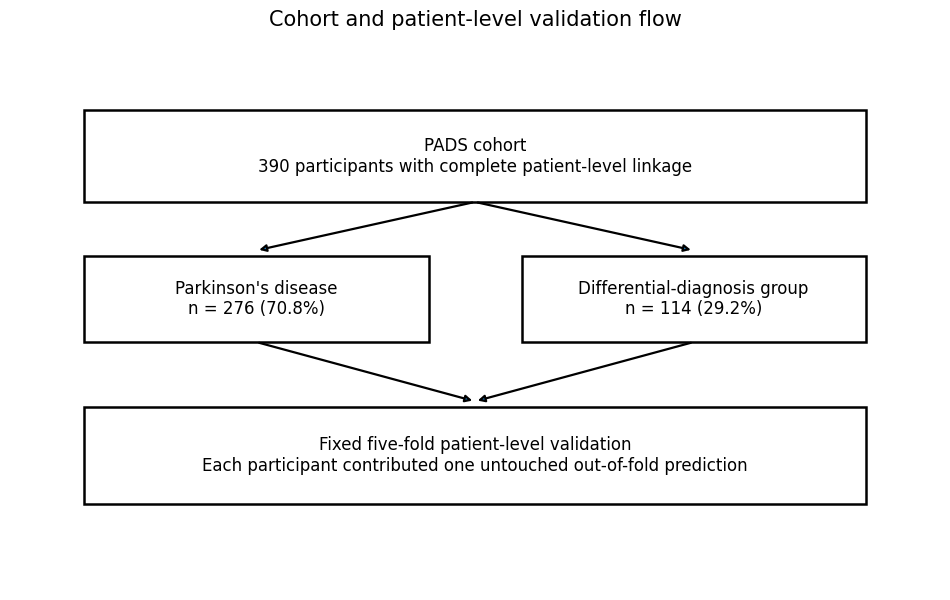

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_1_cohort_and_validation_flow.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_1_cohort_and_validation_flow.pdf


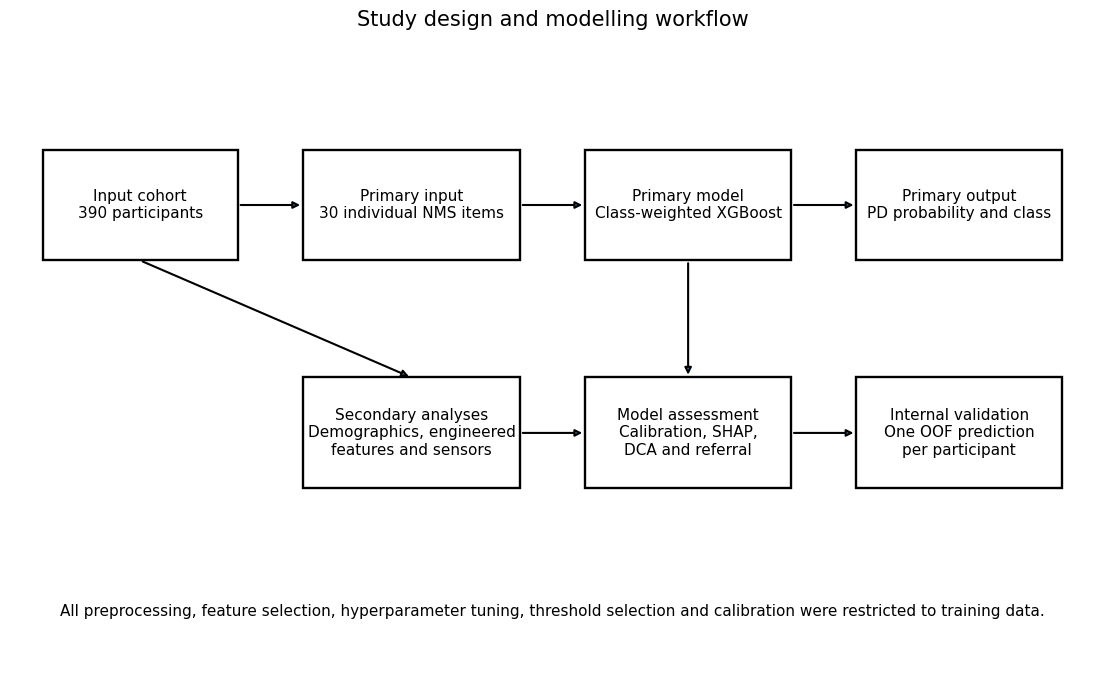

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_2_corrected_modelling_workflow.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_2_corrected_modelling_workflow.pdf


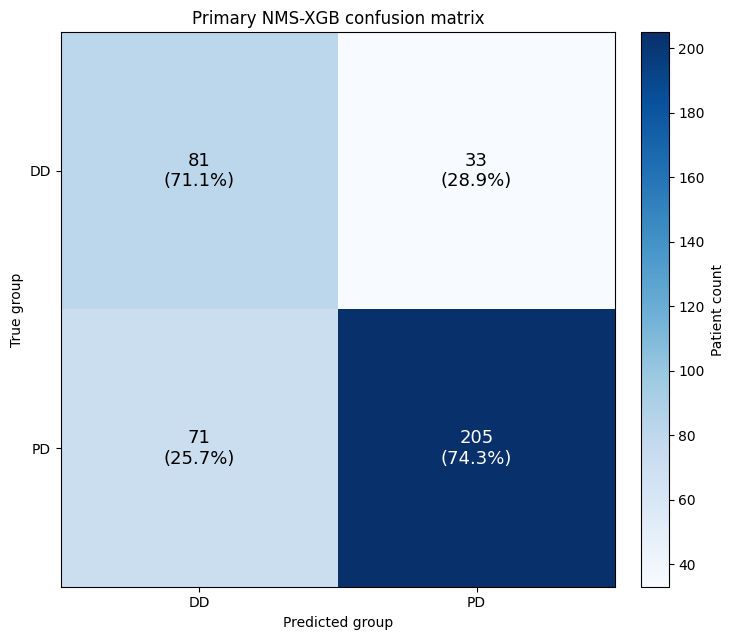

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_3_primary_confusion_matrix.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_3_primary_confusion_matrix.pdf


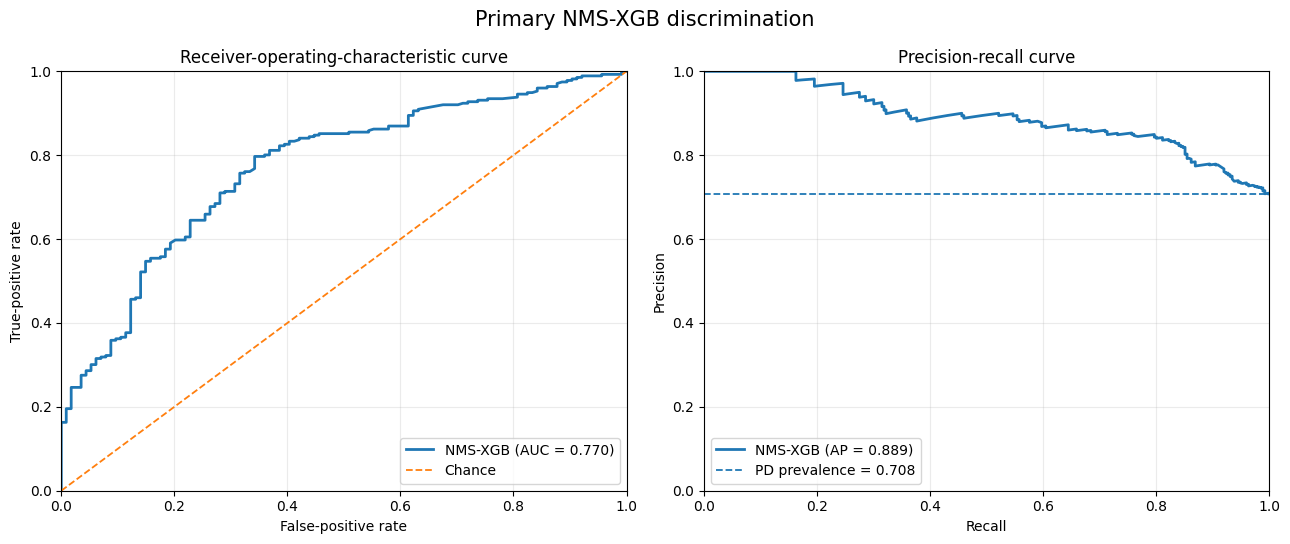

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_4_primary_ROC_and_precision_recall.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_4_primary_ROC_and_precision_recall.pdf


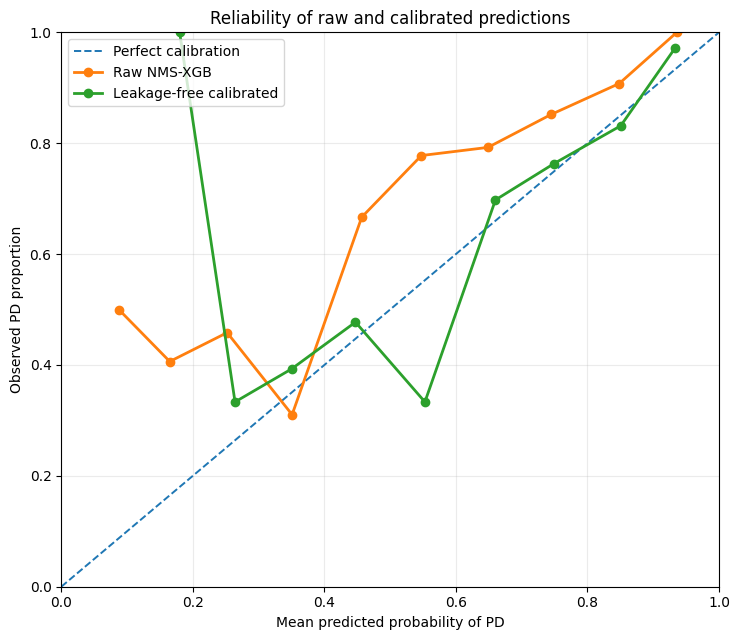

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_5_reliability_diagram.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_5_reliability_diagram.pdf


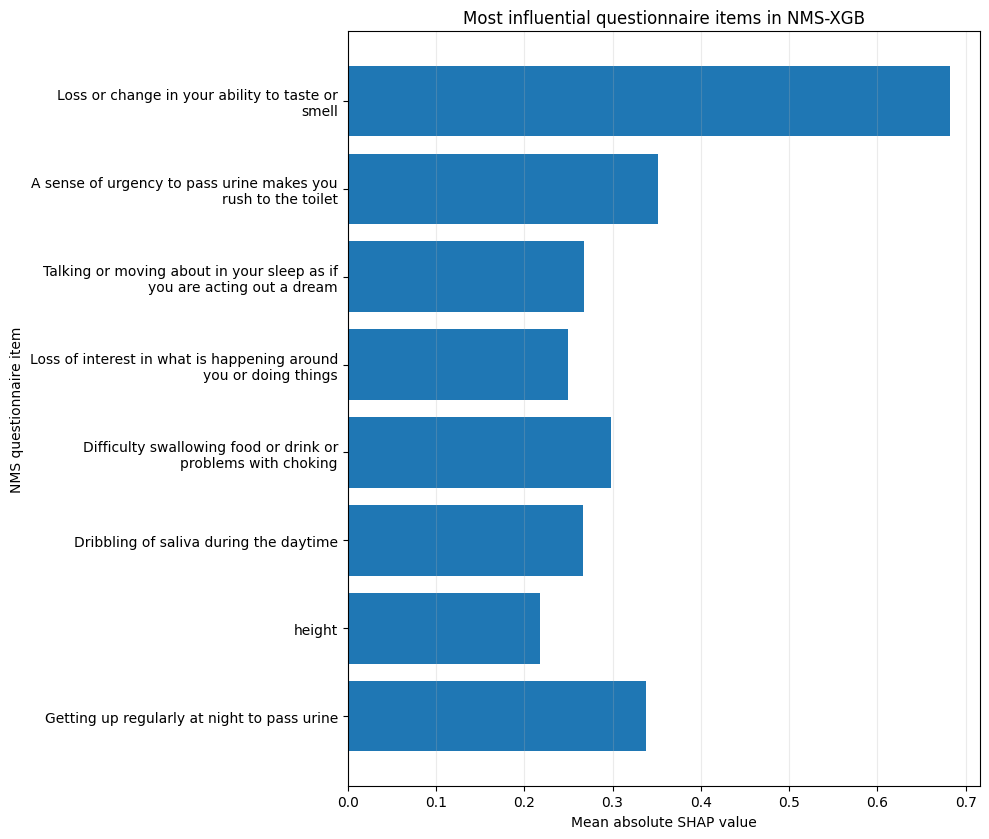

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_6_top15_SHAP_importance.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_6_top15_SHAP_importance.pdf


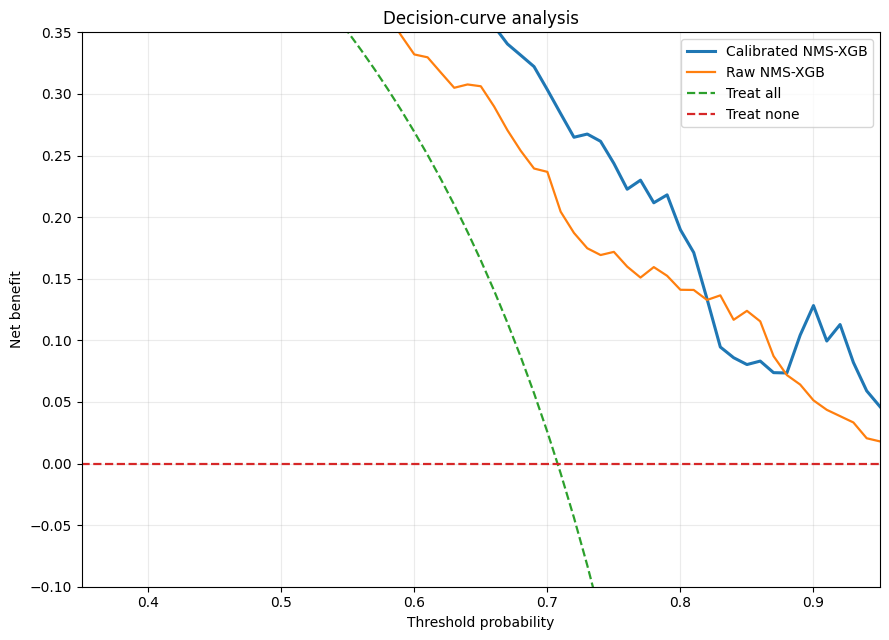

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_7_decision_curve_analysis.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures/Figure_7_decision_curve_analysis.pdf


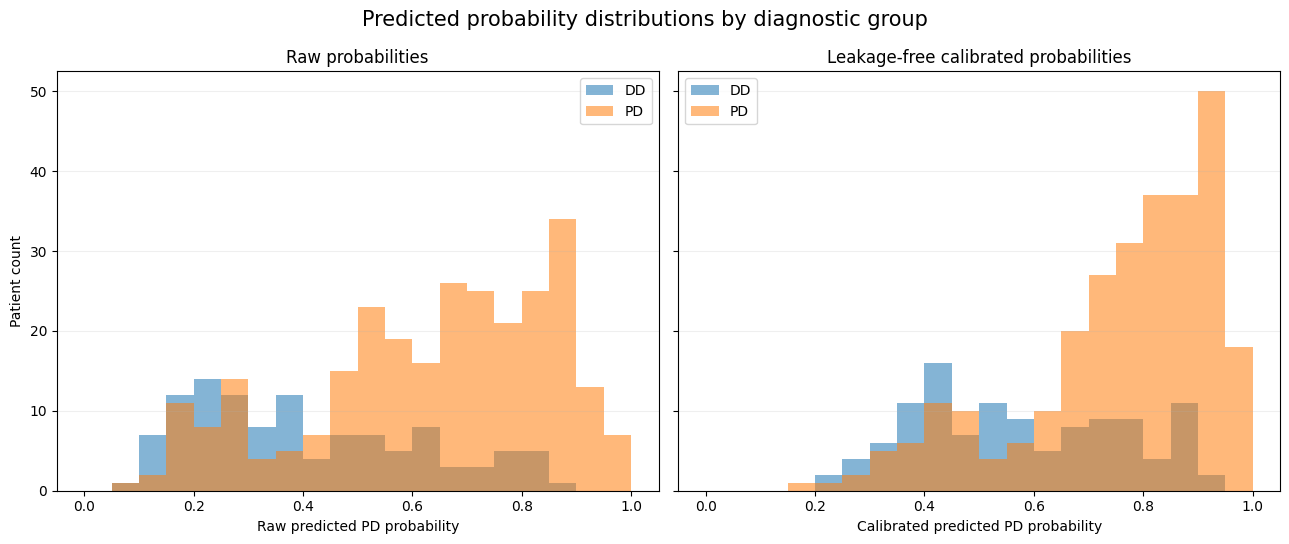

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S1_probability_distributions.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S1_probability_distributions.pdf


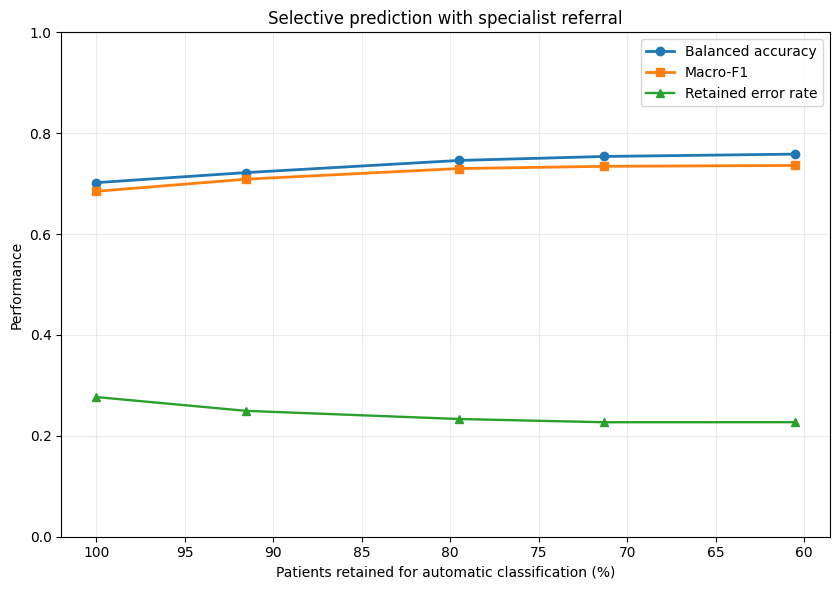

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S2_referral_performance.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S2_referral_performance.pdf


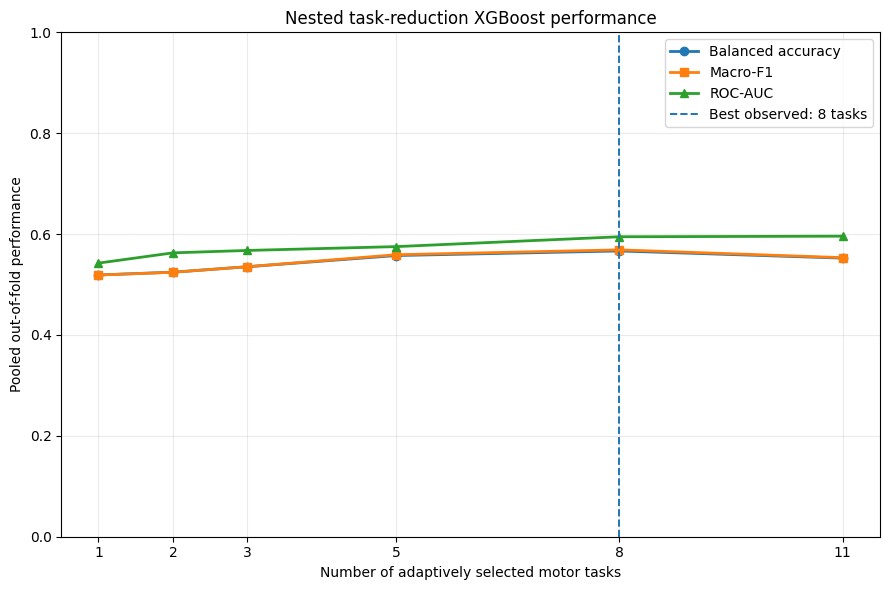

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S4_NTR_performance_by_task_count.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S4_NTR_performance_by_task_count.pdf


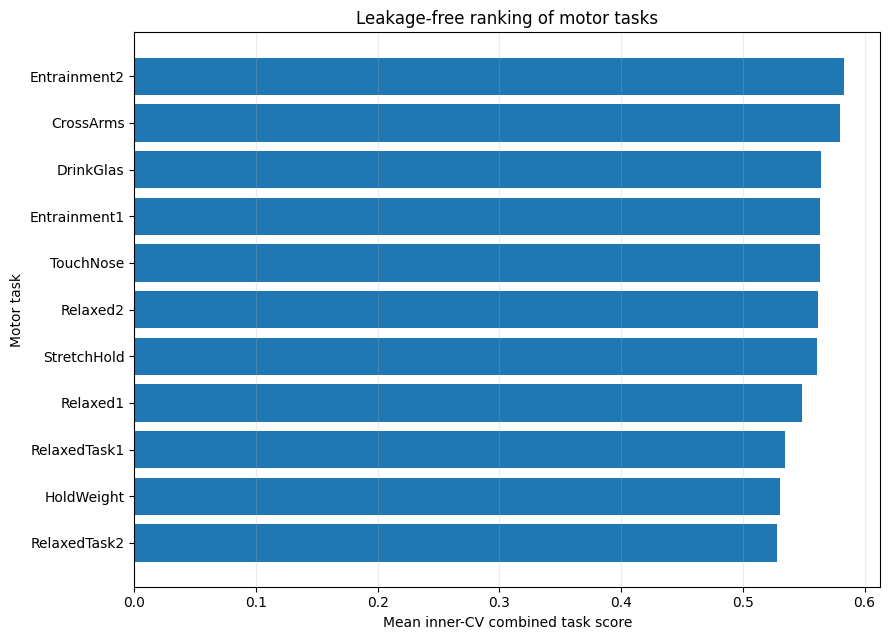

✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S5_NTR_mean_task_ranking.png
✅ Saved: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/supplementary_figures/Figure_S5_NTR_mean_task_ranking.pdf

FIGURE GENERATION SUMMARY

Generated:
 ✅ Figure 1
 ✅ Figure 2
 ✅ Figure 3
 ✅ Figure 4
 ✅ Figure 5
 ✅ Figure 6
 ✅ Figure 7
 ✅ Figure S1
 ✅ Figure S2
 ✅ Figure S4
 ✅ Figure S5

Skipped:
 ⚠️ Figure S3: Model-L questionnaire-reduction summary not found
 ⚠️ Figure S6: Required column not found. Tried: ['subgroup', 'group', 'subgroup_label', 'category']

Main figure folder:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/manuscript_final_postprocessing/publication_figures/main_figures

Supplementary figure folder:
/content/pads_dataset/pad

In [ ]:
# ==================================================================================================
# Q1 MANUSCRIPT — GENERATE ALL MAIN AND SUPPLEMENTARY FIGURES IN ONE CELL
#
# Uses existing Model J, Model K, Model L and Model D/NTR outputs.
# Does not retrain any model.
#
# MAIN FIGURES
# -------------
# Figure 1  Cohort and analysis flow
# Figure 2  Corrected study/model workflow
# Figure 3  Primary NMS-XGB confusion matrix
# Figure 4  Primary NMS-XGB ROC and precision-recall curves
# Figure 5  Raw versus calibrated reliability diagram
# Figure 6  Top-15 questionnaire items by mean absolute SHAP
# Figure 7  Decision-curve analysis
#
# SUPPLEMENTARY FIGURES
# ---------------------
# Figure S1 Predicted probability distributions
# Figure S2 Referral/selective-prediction performance
# Figure S3 Questionnaire-length reduction
# Figure S4 NTR-XGB performance by task count
# Figure S5 NTR-XGB task ranking
# Figure S6 Exploratory subgroup performance, when available
#
# All figures are saved as PNG (300 dpi) and vector PDF.
# ==================================================================================================

from pathlib import Path
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"

OUTPUT_ROOT = (
    PROJECT_DIR
    / "manuscript_final_postprocessing"
    / "publication_figures"
)

MAIN_DIR = OUTPUT_ROOT / "main_figures"
SUPPLEMENT_DIR = OUTPUT_ROOT / "supplementary_figures"

MAIN_DIR.mkdir(parents=True, exist_ok=True)
SUPPLEMENT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 120)
print("Q1 MANUSCRIPT — PUBLICATION FIGURE GENERATION")
print("=" * 120)
print("Main figures         :", MAIN_DIR)
print("Supplementary figures:", SUPPLEMENT_DIR)

# ==================================================================================================
# 2. GENERAL HELPERS
# ==================================================================================================

def find_file(filename, preferred_parts=None):
    """
    Locate one file under project_ready_data.
    Prefer paths containing preferred_parts.
    """
    matches = list(PROJECT_DIR.rglob(filename))

    if not matches:
        return None

    if preferred_parts:
        preferred_parts = [
            str(part).lower()
            for part in preferred_parts
        ]

        preferred = [
            path
            for path in matches
            if all(
                part in str(path).lower()
                for part in preferred_parts
            )
        ]

        if preferred:
            return preferred[0]

    return matches[0]


def detect_column(dataframe, candidates, required=False):
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    lower_map = {
        str(column).lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    if required:
        raise ValueError(
            f"Required column not found. Tried: {candidates}"
        )

    return None


def save_figure(fig, output_directory, basename):
    png_path = output_directory / f"{basename}.png"
    pdf_path = output_directory / f"{basename}.pdf"

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("✅ Saved:", png_path)
    print("✅ Saved:", pdf_path)


def clean_question_text(text, width=42):
    text = str(text).strip()

    replacements = {
        "\n": " ",
        "  ": " ",
        "nms_": "NMS "
    }

    for old, new in replacements.items():
        text = text.replace(old, new)

    return "\n".join(
        textwrap.wrap(
            text,
            width=width
        )
    )


def normalized_patient_id(series):
    return (
        series
        .astype(str)
        .str.replace(".0", "", regex=False)
        .str.zfill(3)
    )


completed_figures = []
skipped_figures = []

# ==================================================================================================
# 3. LOAD PRIMARY MODEL-J PREDICTIONS
# ==================================================================================================

MODEL_J_PREDICTION_FILE = find_file(
    "model_j_patient_predictions.csv",
    preferred_parts=["model_j"]
)

primary_df = None

if MODEL_J_PREDICTION_FILE is not None:

    model_j_all = pd.read_csv(
        MODEL_J_PREDICTION_FILE,
        dtype={"patient_id": str}
    )

    if "configuration" in model_j_all.columns:
        primary_df = model_j_all.loc[
            model_j_all["configuration"]
            == "nms_items_only"
        ].copy()
    else:
        primary_df = model_j_all.copy()

    primary_df = (
        primary_df
        .drop_duplicates(
            subset=["patient_id"],
            keep="last"
        )
        .reset_index(drop=True)
    )

    primary_df["patient_id"] = normalized_patient_id(
        primary_df["patient_id"]
    )

    for column in [
        "true_label",
        "predicted_label",
        "outer_fold"
    ]:
        if column in primary_df.columns:
            primary_df[column] = pd.to_numeric(
                primary_df[column],
                errors="raise"
            ).astype(int)

    primary_probability_column = detect_column(
        primary_df,
        [
            "predicted_probability_pd",
            "probability_pd",
            "predicted_probability"
        ],
        required=True
    )

    primary_df[
        primary_probability_column
    ] = pd.to_numeric(
        primary_df[
            primary_probability_column
        ],
        errors="raise"
    ).astype(float)

    print(
        "\nPrimary predictions:",
        MODEL_J_PREDICTION_FILE
    )
    print(
        "Primary patients:",
        len(primary_df)
    )

else:
    print("\n⚠️ Model-J patient predictions were not found.")

# ==================================================================================================
# 4. FIGURE 1 — COHORT AND ANALYSIS FLOW
# ==================================================================================================

try:
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.axis("off")

    boxes = [
        {
            "xy": (0.08, 0.72),
            "width": 0.84,
            "height": 0.17,
            "text": (
                "PADS cohort\n"
                "390 participants with complete patient-level linkage"
            )
        },
        {
            "xy": (0.08, 0.46),
            "width": 0.37,
            "height": 0.16,
            "text": (
                "Parkinson's disease\n"
                "n = 276 (70.8%)"
            )
        },
        {
            "xy": (0.55, 0.46),
            "width": 0.37,
            "height": 0.16,
            "text": (
                "Differential-diagnosis group\n"
                "n = 114 (29.2%)"
            )
        },
        {
            "xy": (0.08, 0.16),
            "width": 0.84,
            "height": 0.18,
            "text": (
                "Fixed five-fold patient-level validation\n"
                "Each participant contributed one untouched out-of-fold prediction"
            )
        }
    ]

    for box in boxes:
        rectangle = plt.Rectangle(
            box["xy"],
            box["width"],
            box["height"],
            fill=False,
            linewidth=1.8,
            transform=ax.transAxes
        )

        ax.add_patch(rectangle)

        ax.text(
            box["xy"][0] + box["width"] / 2,
            box["xy"][1] + box["height"] / 2,
            box["text"],
            ha="center",
            va="center",
            fontsize=12,
            transform=ax.transAxes
        )

    arrow_properties = {
        "arrowstyle": "-|>",
        "linewidth": 1.6
    }

    ax.annotate(
        "",
        xy=(0.265, 0.63),
        xytext=(0.50, 0.72),
        xycoords=ax.transAxes,
        arrowprops=arrow_properties
    )

    ax.annotate(
        "",
        xy=(0.735, 0.63),
        xytext=(0.50, 0.72),
        xycoords=ax.transAxes,
        arrowprops=arrow_properties
    )

    ax.annotate(
        "",
        xy=(0.50, 0.35),
        xytext=(0.265, 0.46),
        xycoords=ax.transAxes,
        arrowprops=arrow_properties
    )

    ax.annotate(
        "",
        xy=(0.50, 0.35),
        xytext=(0.735, 0.46),
        xycoords=ax.transAxes,
        arrowprops=arrow_properties
    )

    ax.set_title(
        "Cohort and patient-level validation flow",
        fontsize=15,
        pad=18
    )

    save_figure(
        fig,
        MAIN_DIR,
        "Figure_1_cohort_and_validation_flow"
    )

    completed_figures.append("Figure 1")

except Exception as error:
    skipped_figures.append(
        f"Figure 1: {error}"
    )

# ==================================================================================================
# 5. FIGURE 2 — CORRECTED STUDY AND MODEL WORKFLOW
# ==================================================================================================

try:
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.axis("off")

    workflow_boxes = [
        (
            0.03, 0.66, 0.18, 0.18,
            "Input cohort\n390 participants"
        ),
        (
            0.27, 0.66, 0.20, 0.18,
            "Primary input\n30 individual NMS items"
        ),
        (
            0.53, 0.66, 0.19, 0.18,
            "Primary model\nClass-weighted XGBoost"
        ),
        (
            0.78, 0.66, 0.19, 0.18,
            "Primary output\nPD probability and class"
        ),
        (
            0.27, 0.29, 0.20, 0.18,
            "Secondary analyses\nDemographics, engineered\nfeatures and sensors"
        ),
        (
            0.53, 0.29, 0.19, 0.18,
            "Model assessment\nCalibration, SHAP,\nDCA and referral"
        ),
        (
            0.78, 0.29, 0.19, 0.18,
            "Internal validation\nOne OOF prediction\nper participant"
        )
    ]

    for x, y, width, height, text in workflow_boxes:
        rectangle = plt.Rectangle(
            (x, y),
            width,
            height,
            fill=False,
            linewidth=1.7,
            transform=ax.transAxes
        )

        ax.add_patch(rectangle)

        ax.text(
            x + width / 2,
            y + height / 2,
            text,
            ha="center",
            va="center",
            fontsize=11,
            transform=ax.transAxes
        )

    arrow_properties = {
        "arrowstyle": "-|>",
        "linewidth": 1.5
    }

    connections = [
        ((0.21, 0.75), (0.27, 0.75)),
        ((0.47, 0.75), (0.53, 0.75)),
        ((0.72, 0.75), (0.78, 0.75)),
        ((0.12, 0.66), (0.37, 0.47)),
        ((0.47, 0.38), (0.53, 0.38)),
        ((0.72, 0.38), (0.78, 0.38)),
        ((0.625, 0.66), (0.625, 0.47))
    ]

    for start, end in connections:
        ax.annotate(
            "",
            xy=end,
            xytext=start,
            xycoords=ax.transAxes,
            arrowprops=arrow_properties
        )

    ax.text(
        0.50,
        0.09,
        (
            "All preprocessing, feature selection, hyperparameter tuning, "
            "threshold selection and calibration were restricted to training data."
        ),
        ha="center",
        va="center",
        fontsize=11,
        transform=ax.transAxes
    )

    ax.set_title(
        "Study design and modelling workflow",
        fontsize=15,
        pad=18
    )

    save_figure(
        fig,
        MAIN_DIR,
        "Figure_2_corrected_modelling_workflow"
    )

    completed_figures.append("Figure 2")

except Exception as error:
    skipped_figures.append(
        f"Figure 2: {error}"
    )

# ==================================================================================================
# 6. FIGURE 3 — PRIMARY CONFUSION MATRIX
# ==================================================================================================

if primary_df is not None:

    try:
        y_true = primary_df[
            "true_label"
        ].to_numpy(dtype=int)

        y_pred = primary_df[
            "predicted_label"
        ].to_numpy(dtype=int)

        matrix = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )

        row_percentages = (
            matrix
            / matrix.sum(
                axis=1,
                keepdims=True
            )
            * 100
        )

        fig, ax = plt.subplots(figsize=(7.5, 6.5))

        image = ax.imshow(
            matrix,
            interpolation="nearest",
            cmap="Blues"
        )

        fig.colorbar(
            image,
            ax=ax,
            fraction=0.046,
            pad=0.04,
            label="Patient count"
        )

        labels = [
            "DD",
            "PD"
        ]

        ax.set(
            xticks=np.arange(2),
            yticks=np.arange(2),
            xticklabels=labels,
            yticklabels=labels,
            xlabel="Predicted group",
            ylabel="True group",
            title="Primary NMS-XGB confusion matrix"
        )

        threshold = matrix.max() / 2

        for row in range(2):
            for column in range(2):
                ax.text(
                    column,
                    row,
                    (
                        f"{matrix[row, column]}\n"
                        f"({row_percentages[row, column]:.1f}%)"
                    ),
                    ha="center",
                    va="center",
                    fontsize=13,
                    color=(
                        "white"
                        if matrix[row, column] > threshold
                        else "black"
                    )
                )

        fig.tight_layout()

        save_figure(
            fig,
            MAIN_DIR,
            "Figure_3_primary_confusion_matrix"
        )

        completed_figures.append("Figure 3")

    except Exception as error:
        skipped_figures.append(
            f"Figure 3: {error}"
        )

# ==================================================================================================
# 7. FIGURE 4 — ROC AND PRECISION-RECALL CURVES
# ==================================================================================================

if primary_df is not None:

    try:
        y_true = primary_df[
            "true_label"
        ].to_numpy(dtype=int)

        probabilities = primary_df[
            primary_probability_column
        ].to_numpy(dtype=float)

        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            probabilities
        )

        precision, recall, _ = precision_recall_curve(
            y_true,
            probabilities
        )

        roc_auc = roc_auc_score(
            y_true,
            probabilities
        )

        pr_auc = average_precision_score(
            y_true,
            probabilities
        )

        prevalence = np.mean(
            y_true
        )

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 5.5)
        )

        axes[0].plot(
            false_positive_rate,
            true_positive_rate,
            linewidth=2,
            label=f"NMS-XGB (AUC = {roc_auc:.3f})"
        )

        axes[0].plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            linewidth=1.3,
            label="Chance"
        )

        axes[0].set(
            xlabel="False-positive rate",
            ylabel="True-positive rate",
            title="Receiver-operating-characteristic curve",
            xlim=(0, 1),
            ylim=(0, 1)
        )

        axes[0].legend(
            loc="lower right"
        )

        axes[0].grid(
            alpha=0.25
        )

        axes[1].plot(
            recall,
            precision,
            linewidth=2,
            label=f"NMS-XGB (AP = {pr_auc:.3f})"
        )

        axes[1].axhline(
            prevalence,
            linestyle="--",
            linewidth=1.3,
            label=f"PD prevalence = {prevalence:.3f}"
        )

        axes[1].set(
            xlabel="Recall",
            ylabel="Precision",
            title="Precision-recall curve",
            xlim=(0, 1),
            ylim=(0, 1)
        )

        axes[1].legend(
            loc="lower left"
        )

        axes[1].grid(
            alpha=0.25
        )

        fig.suptitle(
            "Primary NMS-XGB discrimination",
            fontsize=15
        )

        fig.tight_layout()

        save_figure(
            fig,
            MAIN_DIR,
            "Figure_4_primary_ROC_and_precision_recall"
        )

        completed_figures.append("Figure 4")

    except Exception as error:
        skipped_figures.append(
            f"Figure 4: {error}"
        )

# ==================================================================================================
# 8. LOAD MODEL-K CALIBRATION OUTPUTS
# ==================================================================================================

MODEL_K_PATIENT_FILE = find_file(
    "model_k_patient_predictions.csv",
    preferred_parts=["model_k"]
)

MODEL_K_RELIABILITY_FILE = find_file(
    "model_k_reliability_table.csv",
    preferred_parts=["model_k"]
)

MODEL_K_DCA_FILE = find_file(
    "model_k_decision_curve.csv",
    preferred_parts=["model_k"]
)

MODEL_K_REFERRAL_FILE = find_file(
    "model_k_referral_summary.csv",
    preferred_parts=["model_k"]
)

model_k_patient_df = None

if MODEL_K_PATIENT_FILE is not None:
    model_k_patient_df = pd.read_csv(
        MODEL_K_PATIENT_FILE,
        dtype={"patient_id": str}
    )

# ==================================================================================================
# 9. FIGURE 5 — RELIABILITY DIAGRAM
# ==================================================================================================

try:
    if MODEL_K_RELIABILITY_FILE is None:
        raise FileNotFoundError(
            "model_k_reliability_table.csv not found"
        )

    reliability_df = pd.read_csv(
        MODEL_K_RELIABILITY_FILE
    )

    model_column = detect_column(
        reliability_df,
        ["model"],
        required=True
    )

    predicted_column = detect_column(
        reliability_df,
        ["mean_predicted_probability"],
        required=True
    )

    observed_column = detect_column(
        reliability_df,
        ["observed_pd_fraction"],
        required=True
    )

    count_column = detect_column(
        reliability_df,
        ["patient_count"],
        required=False
    )

    fig, ax = plt.subplots(figsize=(7.5, 6.5))

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.4,
        label="Perfect calibration"
    )

    display_names = {
        "raw_model_j": "Raw NMS-XGB",
        "leakage_free_calibrated": "Leakage-free calibrated"
    }

    for model_name in reliability_df[
        model_column
    ].dropna().unique():

        subset = reliability_df.loc[
            reliability_df[
                model_column
            ] == model_name
        ].sort_values(
            predicted_column
        )

        ax.plot(
            subset[predicted_column],
            subset[observed_column],
            marker="o",
            linewidth=2,
            label=display_names.get(
                model_name,
                str(model_name)
            )
        )

    ax.set(
        xlabel="Mean predicted probability of PD",
        ylabel="Observed PD proportion",
        title="Reliability of raw and calibrated predictions",
        xlim=(0, 1),
        ylim=(0, 1)
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        loc="upper left"
    )

    if count_column is not None:
        counts = reliability_df[
            count_column
        ].dropna().unique()

        if len(counts) == 1:
            ax.text(
                0.98,
                0.03,
                f"n = {int(counts[0])} per bin",
                ha="right",
                va="bottom",
                transform=ax.transAxes,
                fontsize=10
            )

    fig.tight_layout()

    save_figure(
        fig,
        MAIN_DIR,
        "Figure_5_reliability_diagram"
    )

    completed_figures.append("Figure 5")

except Exception as error:
    skipped_figures.append(
        f"Figure 5: {error}"
    )

# ==================================================================================================
# 10. FIGURE 6 — TOP-15 SHAP IMPORTANCE
# ==================================================================================================

try:
    SHAP_IMPORTANCE_FILE = find_file(
        "model_j_global_shap_importance.csv",
        preferred_parts=["model_j"]
    )

    SHAP_MAPPING_FILE = find_file(
        "model_j_nms_question_mapping.csv",
        preferred_parts=["model_j"]
    )

    if SHAP_IMPORTANCE_FILE is None:
        raise FileNotFoundError(
            "model_j_global_shap_importance.csv not found"
        )

    shap_df = pd.read_csv(
        SHAP_IMPORTANCE_FILE
    )

    feature_column = detect_column(
        shap_df,
        [
            "feature",
            "feature_name",
            "variable"
        ],
        required=True
    )

    importance_column = detect_column(
        shap_df,
        [
            "mean_absolute_shap",
            "mean_abs_shap",
            "importance",
            "mean_shap_absolute"
        ],
        required=True
    )

    if SHAP_MAPPING_FILE is not None:
        mapping_df = pd.read_csv(
            SHAP_MAPPING_FILE
        )

        mapping_feature_column = detect_column(
            mapping_df,
            [
                "feature",
                "feature_name"
            ],
            required=True
        )

        mapping_text_column = detect_column(
            mapping_df,
            [
                "question_text",
                "display_name",
                "question",
                "label"
            ],
            required=True
        )

        mapping_df = mapping_df[
            [
                mapping_feature_column,
                mapping_text_column
            ]
        ].drop_duplicates()

        mapping_df.columns = [
            feature_column,
            "question_display"
        ]

        shap_df = shap_df.merge(
            mapping_df,
            on=feature_column,
            how="left"
        )

    if "question_display" not in shap_df.columns:
        shap_df[
            "question_display"
        ] = shap_df[
            feature_column
        ]

    shap_df[
        "question_display"
    ] = shap_df[
        "question_display"
    ].fillna(
        shap_df[
            feature_column
        ]
    )

    top_shap = (
        shap_df
        .sort_values(
            importance_column,
            ascending=False
        )
        .head(15)
        .sort_values(
            importance_column,
            ascending=True
        )
        .copy()
    )

    top_shap[
        "plot_label"
    ] = top_shap[
        "question_display"
    ].apply(
        lambda value: clean_question_text(
            value,
            width=46
        )
    )

    fig, ax = plt.subplots(figsize=(10, 8.5))

    ax.barh(
        top_shap[
            "plot_label"
        ],
        top_shap[
            importance_column
        ]
    )

    ax.set(
        xlabel="Mean absolute SHAP value",
        ylabel="NMS questionnaire item",
        title="Most influential questionnaire items in NMS-XGB"
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    fig.tight_layout()

    save_figure(
        fig,
        MAIN_DIR,
        "Figure_6_top15_SHAP_importance"
    )

    completed_figures.append("Figure 6")

except Exception as error:
    skipped_figures.append(
        f"Figure 6: {error}"
    )

# ==================================================================================================
# 11. FIGURE 7 — DECISION-CURVE ANALYSIS
# ==================================================================================================

try:
    if MODEL_K_DCA_FILE is None:
        raise FileNotFoundError(
            "model_k_decision_curve.csv not found"
        )

    dca_df = pd.read_csv(
        MODEL_K_DCA_FILE
    )

    threshold_column = detect_column(
        dca_df,
        [
            "threshold_probability",
            "threshold"
        ],
        required=True
    )

    strategy_column = detect_column(
        dca_df,
        ["strategy"],
        required=True
    )

    net_benefit_column = detect_column(
        dca_df,
        ["net_benefit"],
        required=True
    )

    strategy_names = {
        "calibrated_model": "Calibrated NMS-XGB",
        "raw_model_j": "Raw NMS-XGB",
        "treat_all": "Treat all",
        "treat_none": "Treat none"
    }

    fig, ax = plt.subplots(figsize=(9, 6.5))

    for strategy in [
        "calibrated_model",
        "raw_model_j",
        "treat_all",
        "treat_none"
    ]:

        subset = dca_df.loc[
            dca_df[
                strategy_column
            ] == strategy
        ].sort_values(
            threshold_column
        )

        if subset.empty:
            continue

        line_style = (
            "--"
            if strategy in [
                "treat_all",
                "treat_none"
            ]
            else "-"
        )

        ax.plot(
            subset[
                threshold_column
            ],
            subset[
                net_benefit_column
            ],
            linewidth=(
                2.2
                if strategy == "calibrated_model"
                else 1.6
            ),
            linestyle=line_style,
            label=strategy_names.get(
                strategy,
                strategy
            )
        )

    ax.set(
        xlabel="Threshold probability",
        ylabel="Net benefit",
        title="Decision-curve analysis",
        xlim=(0.35, 0.95),
        ylim=(-0.10, 0.35)
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        loc="best"
    )

    fig.tight_layout()

    save_figure(
        fig,
        MAIN_DIR,
        "Figure_7_decision_curve_analysis"
    )

    completed_figures.append("Figure 7")

except Exception as error:
    skipped_figures.append(
        f"Figure 7: {error}"
    )

# ==================================================================================================
# 12. FIGURE S1 — RAW AND CALIBRATED PROBABILITY DISTRIBUTIONS
# ==================================================================================================

try:
    if model_k_patient_df is None:
        raise FileNotFoundError(
            "model_k_patient_predictions.csv not found"
        )

    raw_probability_column = detect_column(
        model_k_patient_df,
        [
            "raw_probability_pd",
            "predicted_probability_pd"
        ],
        required=True
    )

    calibrated_probability_column = detect_column(
        model_k_patient_df,
        [
            "calibrated_probability_pd"
        ],
        required=True
    )

    label_column = detect_column(
        model_k_patient_df,
        ["true_label"],
        required=True
    )

    bins = np.linspace(
        0,
        1,
        21
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5.5),
        sharey=True
    )

    for label_value, label_name in [
        (0, "DD"),
        (1, "PD")
    ]:
        mask = (
            model_k_patient_df[
                label_column
            ] == label_value
        )

        axes[0].hist(
            model_k_patient_df.loc[
                mask,
                raw_probability_column
            ],
            bins=bins,
            alpha=0.55,
            label=label_name
        )

        axes[1].hist(
            model_k_patient_df.loc[
                mask,
                calibrated_probability_column
            ],
            bins=bins,
            alpha=0.55,
            label=label_name
        )

    axes[0].set(
        xlabel="Raw predicted PD probability",
        ylabel="Patient count",
        title="Raw probabilities"
    )

    axes[1].set(
        xlabel="Calibrated predicted PD probability",
        title="Leakage-free calibrated probabilities"
    )

    for ax in axes:
        ax.legend()
        ax.grid(
            axis="y",
            alpha=0.20
        )

    fig.suptitle(
        "Predicted probability distributions by diagnostic group",
        fontsize=15
    )

    fig.tight_layout()

    save_figure(
        fig,
        SUPPLEMENT_DIR,
        "Figure_S1_probability_distributions"
    )

    completed_figures.append("Figure S1")

except Exception as error:
    skipped_figures.append(
        f"Figure S1: {error}"
    )

# ==================================================================================================
# 13. FIGURE S2 — REFERRAL / SELECTIVE-PREDICTION PERFORMANCE
# ==================================================================================================

try:
    if MODEL_K_REFERRAL_FILE is None:
        raise FileNotFoundError(
            "model_k_referral_summary.csv not found"
        )

    referral_df = pd.read_csv(
        MODEL_K_REFERRAL_FILE
    )

    target_coverage_column = detect_column(
        referral_df,
        [
            "target_retained_coverage"
        ],
        required=True
    )

    actual_coverage_column = detect_column(
        referral_df,
        [
            "mean_actual_retained_coverage",
            "actual_retained_coverage"
        ],
        required=True
    )

    ba_column = detect_column(
        referral_df,
        [
            "mean_retained_balanced_accuracy",
            "retained_balanced_accuracy"
        ],
        required=True
    )

    macro_f1_column = detect_column(
        referral_df,
        [
            "mean_retained_macro_f1",
            "retained_macro_f1"
        ],
        required=False
    )

    error_column = detect_column(
        referral_df,
        [
            "mean_retained_error_rate",
            "retained_error_rate"
        ],
        required=False
    )

    plot_df = referral_df.sort_values(
        actual_coverage_column
    ).copy()

    plot_df[
        "coverage_percent"
    ] = (
        plot_df[
            actual_coverage_column
        ]
        * 100
    )

    fig, ax = plt.subplots(figsize=(8.5, 6))

    ax.plot(
        plot_df[
            "coverage_percent"
        ],
        plot_df[
            ba_column
        ],
        marker="o",
        linewidth=2,
        label="Balanced accuracy"
    )

    if macro_f1_column is not None:
        ax.plot(
            plot_df[
                "coverage_percent"
            ],
            plot_df[
                macro_f1_column
            ],
            marker="s",
            linewidth=2,
            label="Macro-F1"
        )

    if error_column is not None:
        ax.plot(
            plot_df[
                "coverage_percent"
            ],
            plot_df[
                error_column
            ],
            marker="^",
            linewidth=1.7,
            label="Retained error rate"
        )

    ax.set(
        xlabel="Patients retained for automatic classification (%)",
        ylabel="Performance",
        title="Selective prediction with specialist referral",
        ylim=(0, 1)
    )

    ax.invert_xaxis()

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        loc="best"
    )

    fig.tight_layout()

    save_figure(
        fig,
        SUPPLEMENT_DIR,
        "Figure_S2_referral_performance"
    )

    completed_figures.append("Figure S2")

except Exception as error:
    skipped_figures.append(
        f"Figure S2: {error}"
    )

# ==================================================================================================
# 14. FIGURE S3 — QUESTIONNAIRE-LENGTH REDUCTION
# ==================================================================================================

try:
    MODEL_L_OVERALL_FILE = find_file(
        "model_l_overall_question_count_comparison.csv",
        preferred_parts=["model_l"]
    )

    if MODEL_L_OVERALL_FILE is None:
        raise FileNotFoundError(
            "Model-L questionnaire-reduction summary not found"
        )

    model_l_df = pd.read_csv(
        MODEL_L_OVERALL_FILE
    ).sort_values(
        "question_count"
    )

    fig, ax = plt.subplots(figsize=(8.5, 6))

    ax.plot(
        model_l_df[
            "question_count"
        ],
        model_l_df[
            "balanced_accuracy"
        ],
        marker="o",
        linewidth=2,
        label="Balanced accuracy"
    )

    ax.plot(
        model_l_df[
            "question_count"
        ],
        model_l_df[
            "macro_f1"
        ],
        marker="s",
        linewidth=2,
        label="Macro-F1"
    )

    ax.set(
        xlabel="Number of NMS questionnaire items",
        ylabel="Out-of-fold performance",
        title="Questionnaire-length reduction analysis",
        ylim=(0, 1)
    )

    ax.set_xticks(
        model_l_df[
            "question_count"
        ].tolist()
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend()

    fig.tight_layout()

    save_figure(
        fig,
        SUPPLEMENT_DIR,
        "Figure_S3_questionnaire_length_reduction"
    )

    completed_figures.append("Figure S3")

except Exception as error:
    skipped_figures.append(
        f"Figure S3: {error}"
    )

# ==================================================================================================
# 15. FIGURE S4 — NTR-XGB PERFORMANCE BY TASK COUNT
# ==================================================================================================

try:
    NTR_OVERALL_FILE = find_file(
        "minimum_task_overall_summary.csv",
        preferred_parts=["model_d"]
    )

    if NTR_OVERALL_FILE is None:
        raise FileNotFoundError(
            "minimum_task_overall_summary.csv not found"
        )

    ntr_df = pd.read_csv(
        NTR_OVERALL_FILE
    ).sort_values(
        "task_count"
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    for metric, label, marker in [
        (
            "balanced_accuracy",
            "Balanced accuracy",
            "o"
        ),
        (
            "macro_f1",
            "Macro-F1",
            "s"
        ),
        (
            "roc_auc",
            "ROC-AUC",
            "^"
        )
    ]:
        if metric in ntr_df.columns:
            ax.plot(
                ntr_df[
                    "task_count"
                ],
                ntr_df[
                    metric
                ],
                marker=marker,
                linewidth=2,
                label=label
            )

    best_task_count = int(
        ntr_df.sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "roc_auc"
            ],
            ascending=False
        ).iloc[0][
            "task_count"
        ]
    )

    ax.axvline(
        best_task_count,
        linestyle="--",
        linewidth=1.4,
        label=f"Best observed: {best_task_count} tasks"
    )

    ax.set(
        xlabel="Number of adaptively selected motor tasks",
        ylabel="Pooled out-of-fold performance",
        title="Nested task-reduction XGBoost performance",
        ylim=(0, 1)
    )

    ax.set_xticks(
        ntr_df[
            "task_count"
        ].tolist()
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        loc="best"
    )

    fig.tight_layout()

    save_figure(
        fig,
        SUPPLEMENT_DIR,
        "Figure_S4_NTR_performance_by_task_count"
    )

    completed_figures.append("Figure S4")

except Exception as error:
    skipped_figures.append(
        f"Figure S4: {error}"
    )

# ==================================================================================================
# 16. FIGURE S5 — NTR TASK RANKING
# ==================================================================================================

try:
    NTR_RANKING_FILE = find_file(
        "mean_task_ranking_across_folds.csv",
        preferred_parts=["model_d"]
    )

    if NTR_RANKING_FILE is None:
        raise FileNotFoundError(
            "mean_task_ranking_across_folds.csv not found"
        )

    ranking_df = pd.read_csv(
        NTR_RANKING_FILE
    )

    task_column = detect_column(
        ranking_df,
        ["task"],
        required=True
    )

    score_column = detect_column(
        ranking_df,
        [
            "mean_inner_combined_score",
            "mean_combined_score"
        ],
        required=True
    )

    ranking_df = ranking_df.sort_values(
        score_column,
        ascending=True
    )

    fig, ax = plt.subplots(figsize=(9, 6.5))

    ax.barh(
        ranking_df[
            task_column
        ],
        ranking_df[
            score_column
        ]
    )

    ax.set(
        xlabel="Mean inner-CV combined task score",
        ylabel="Motor task",
        title="Leakage-free ranking of motor tasks"
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    fig.tight_layout()

    save_figure(
        fig,
        SUPPLEMENT_DIR,
        "Figure_S5_NTR_mean_task_ranking"
    )

    completed_figures.append("Figure S5")

except Exception as error:
    skipped_figures.append(
        f"Figure S5: {error}"
    )

# ==================================================================================================
# 17. FIGURE S6 — EXPLORATORY SUBGROUP PERFORMANCE
# ==================================================================================================

try:
    subgroup_candidates = (
        list(
            PROJECT_DIR.rglob(
                "*subgroup*confidence*.csv"
            )
        )
        + list(
            PROJECT_DIR.rglob(
                "*subgroup*ci*.csv"
            )
        )
        + list(
            PROJECT_DIR.rglob(
                "model_j_subgroup*.csv"
            )
        )
    )

    subgroup_candidates = list(
        dict.fromkeys(
            subgroup_candidates
        )
    )

    if not subgroup_candidates:
        raise FileNotFoundError(
            "Subgroup confidence-interval file not found"
        )

    subgroup_file = subgroup_candidates[0]
    subgroup_df = pd.read_csv(
        subgroup_file
    )

    subgroup_column = detect_column(
        subgroup_df,
        [
            "subgroup",
            "group",
            "subgroup_label",
            "category"
        ],
        required=True
    )

    estimate_column = detect_column(
        subgroup_df,
        [
            "balanced_accuracy",
            "estimate",
            "value"
        ],
        required=True
    )

    lower_column = detect_column(
        subgroup_df,
        [
            "ci_95_lower",
            "ci_lower",
            "lower"
        ],
        required=True
    )

    upper_column = detect_column(
        subgroup_df,
        [
            "ci_95_upper",
            "ci_upper",
            "upper"
        ],
        required=True
    )

    sample_size_column = detect_column(
        subgroup_df,
        [
            "patients",
            "n",
            "sample_size"
        ],
        required=False
    )

    subgroup_df = subgroup_df.dropna(
        subset=[
            subgroup_column,
            estimate_column,
            lower_column,
            upper_column
        ]
    ).copy()

    subgroup_df = subgroup_df.sort_values(
        estimate_column,
        ascending=True
    )

    labels = subgroup_df[
        subgroup_column
    ].astype(str).tolist()

    if sample_size_column is not None:
        labels = [
            f"{label} (n={int(n)})"
            for label, n
            in zip(
                labels,
                subgroup_df[
                    sample_size_column
                ]
            )
        ]

    positions = np.arange(
        len(subgroup_df)
    )

    estimates = subgroup_df[
        estimate_column
    ].to_numpy(dtype=float)

    lower_errors = (
        estimates
        - subgroup_df[
            lower_column
        ].to_numpy(dtype=float)
    )

    upper_errors = (
        subgroup_df[
            upper_column
        ].to_numpy(dtype=float)
        - estimates
    )

    fig, ax = plt.subplots(
        figsize=(
            9,
            max(
                5,
                0.55 * len(subgroup_df)
            )
        )
    )

    ax.errorbar(
        estimates,
        positions,
        xerr=[
            lower_errors,
            upper_errors
        ],
        fmt="o",
        capsize=4,
        linewidth=1.5
    )

    ax.axvline(
        0.5,
        linestyle="--",
        linewidth=1.2,
        label="Chance-level balanced accuracy"
    )

    ax.set_yticks(
        positions
    )

    ax.set_yticklabels(
        labels
    )

    ax.set(
        xlabel="Balanced accuracy with 95% bootstrap CI",
        ylabel="Exploratory subgroup",
        title="Exploratory subgroup performance",
        xlim=(0, 1)
    )

    ax.grid(
        axis="x",
        alpha=0.25
    )

    ax.legend(
        loc="lower right"
    )

    fig.tight_layout()

    save_figure(
        fig,
        SUPPLEMENT_DIR,
        "Figure_S6_exploratory_subgroup_performance"
    )

    completed_figures.append("Figure S6")

except Exception as error:
    skipped_figures.append(
        f"Figure S6: {error}"
    )

# ==================================================================================================
# 18. SAVE FIGURE MANIFEST
# ==================================================================================================

manifest_rows = []

for figure_name in completed_figures:
    manifest_rows.append({
        "figure": figure_name,
        "status": "Generated"
    })

for skipped in skipped_figures:
    manifest_rows.append({
        "figure": skipped.split(":")[0],
        "status": "Skipped",
        "reason": ":".join(
            skipped.split(":")[1:]
        ).strip()
    })

manifest_df = pd.DataFrame(
    manifest_rows
)

manifest_df.to_csv(
    OUTPUT_ROOT
    / "publication_figure_manifest.csv",
    index=False
)

print("\n" + "=" * 120)
print("FIGURE GENERATION SUMMARY")
print("=" * 120)

print("\nGenerated:")
for figure_name in completed_figures:
    print(" ✅", figure_name)

if skipped_figures:
    print("\nSkipped:")
    for skipped in skipped_figures:
        print(" ⚠️", skipped)

print("\nMain figure folder:")
print(MAIN_DIR)

print("\nSupplementary figure folder:")
print(SUPPLEMENT_DIR)

print("\nManifest:")
print(
    OUTPUT_ROOT
    / "publication_figure_manifest.csv"
)

print("\n✅ Publication figure-generation cell completed.")